In [1]:
import csv
import warnings
import zipfile
from collections import Counter
import requests

import chemparse
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
from netgraph import get_multipartite_layout
from networkx.algorithms import bipartite

from utilities import *
from chirality_ratio import *
from network_expansion import *

tqdm.pandas()

# Matplotlib defaults
font = {"sans-serif": "DejaVu Sans", "size": 22}
for key, value in font.items():
    plt.rcParams.update({"font." + key: value})

# SI Figure details
fig_count = 1
fig_path = "../Figures/SIFigures/SIFig_"

# Colors

achiral_color = "#FFC012"
chiral_color = "#34CCFF"
rgba = lambda x: matplotlib.colors.to_rgba(x)
colors = dict(
    achiral_color  = "#FFC012",
    chiral_color   = "#34CCFF",
    sum_color      = "limegreen",
    mixed_color    = "green",
    gen_color      = "Greys",
    dropout_color  = "darkorange",
    sizefilter_color = "firebrick",
    mg_color = "#009E73",
    e_color = "#E69F03",
    b_color = "#0B77B5",
    a_color = "#D65E00",
    pt_color = "#EA9999",
    chnops_color = "#477C7D",
    kegg_color = "#AA0E35"
    )

keggC_df = C_df



# JGI 

Includes full achiral/chiral crossover plot

Full domain-specific scatter plots and achiral/crossover plots, plus metagenomes, are in sampling section

## Scatter Plots of chirality of individual samples

In [2]:
def find_fit(X, Y, color, ax):
    slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
    print('Slope: {:.6f}'.format(slope), 'Intercept: {:.6f}'.format(intercept),
          'R-squared: {:.6f}'.format(r_value ** 2), 'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=0, stop=max(X), num=100)
    ax.plot(x_dummy, slope * x_dummy + intercept, color=color)
    ax.fill_between(x_dummy, slope * x_dummy + intercept - std_err, slope * x_dummy + intercept + std_err, color=color,
                    alpha=0.2)


## Chiral/Achiral crossover (by domain)

In [3]:
domains = pd.read_csv('../Data/omics/compound2occurrence.csv', header=0, index_col=0)
domains = domains.rename(columns={'Eukaryota': 'Eukarya'})
num_samples = domains.loc['N', :].copy()
domains = domains.drop(index='N').astype(bool)
domains['all'] = domains.any(axis=1)
domains = (domains[domains].T * keggC_df.loc[domains.index, 'is_chiral']).T
domain_chiral_fractions = domains.groupby(by=keggC_df.loc[domains.index, 'n_heavy_atoms']).mean()
domain_achiral_fractions = 1 - domain_chiral_fractions

domain_colors = {'Metagenome': rgba("#009E73"),
                 'Bacteria': rgba("#0B77B5"),
                 'Eukarya': rgba("#E69F03"),
                 'Archaea': rgba("#D65E00")}

#### Fraction chiral/achiral with standard deviations

No domain data attached

In [4]:
# Import enzymes for each metagenome
tid2ec_all = pd.read_csv('../Data/omics/tid2ecs.csv.zip', compression='zip', header=0, index_col=0, na_filter=False).T.astype(bool)
tid2domain = pd.read_csv('../Data/omics/tid2domain.csv', header=0, index_col=0).iloc[:, 0].replace('Eukaryota', 'Eukarya')
tid2ec = tid2ec_all.loc[:,tid2domain[tid2domain == "Metagenome"].index]

# IMPORTANT: Use new chiral-centers count to make df of cpds present in each mg. cols are MGs; rows are compound IDs.
# NaN=not present in MG, True=chiral + present, False=achiral + present.
rn2ec = pd.read_csv(reaction_file, usecols=['id', 'ec', 'reaction'],
                    converters={'ec': lambda x: [i for i in x.split() if '-' not in i]})
rn2ec['compounds'] = rn2ec['reaction'].str.findall(r'(C\d{5})').map(lambda x: list(set(x)))
ec2rns = rn2ec.explode('ec').dropna(subset='ec').groupby('ec')['id'].unique()
ec2cps = rn2ec.explode('ec').dropna(subset='ec').explode('compounds').groupby('ec')['compounds'].unique()
tid2cp = tid2ec.assign(compounds=ec2cps).dropna(subset='compounds').explode('compounds').set_index('compounds').groupby(level=0).any()
tid2chiral = tid2cp.astype(int)[tid2cp].mul(keggC_df.loc[tid2cp.index, 'is_chiral'], axis=0)
cps_present = tid2chiral

# What we plotted initially: Chiral fraction for compounds with a given heavy-atom count, for each metagenome
heavy_atom_count = keggC_df['n_heavy_atoms']
chiral_fracs_per_mg = cps_present.groupby(by=heavy_atom_count).mean()
chiral_fracs_per_mg = (chiral_fracs_per_mg.agg(['mean', 'std'], axis=1).add_prefix('chiral_', axis=1).reset_index()
                       .assign(achiral_mean=lambda x: 1 - x['chiral_mean'],
                               achiral_std=lambda x: x['chiral_std']))

if 'compound_id' not in keggC_df.columns:
        # Reset index to get back to the original dataframe
        keggC_df = keggC_df.reset_index() 

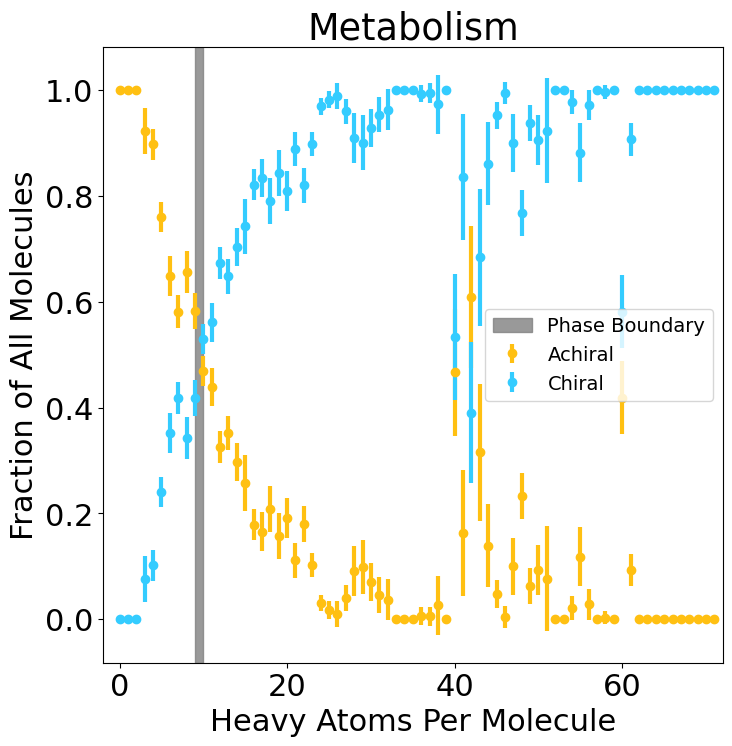

In [5]:
# fig_count = 1
fig, ax = plt.subplots(figsize=(8, 8))

plt.errorbar(x=chiral_fracs_per_mg['n_heavy_atoms'], y=chiral_fracs_per_mg['achiral_mean'],
             yerr=chiral_fracs_per_mg['achiral_std'],
             fmt="o", linewidth=3, label="Achiral", color=achiral_color)
plt.errorbar(x=chiral_fracs_per_mg['n_heavy_atoms'], y=chiral_fracs_per_mg['chiral_mean'],
             yerr=chiral_fracs_per_mg['chiral_std'],
             fmt="o", linewidth=3, label="Chiral", color=chiral_color)
plt.axvspan(9, 10, alpha=0.8, color='grey', label="Phase Boundary")

plt.xlim(-2, 72)
plt.title("Metabolism")
plt.legend(prop={"size": 14})
plt.xlabel("Heavy Atoms Per Molecule")
plt.ylabel("Fraction of All Molecules")

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")

fig_count += 1

#### GDB / JGI / Chiral Order Parameter, no x-limits

In [6]:
gdb_df = pd.read_csv("../Data/GDB_output.csv", index_col=0, usecols=[1, 2, 3])
## GDB chiral order parameter (cop = "Chiral Order Parameter")
gdb_counts_df = pd.read_csv("../Data/GDB_raw_counts.csv", index_col=0, usecols=[1, 2, 3])
gdb_cop = (gdb_counts_df['count_chiral'] / gdb_counts_df.sum(axis=1))  # same as:  gdb_df['fraction_chiral']
JGI_cop = domains['all'].dropna().groupby(by=keggC_df.set_index('compound_id')['n_heavy_atoms']).mean().loc[:70].rename(
    'Metabolism')

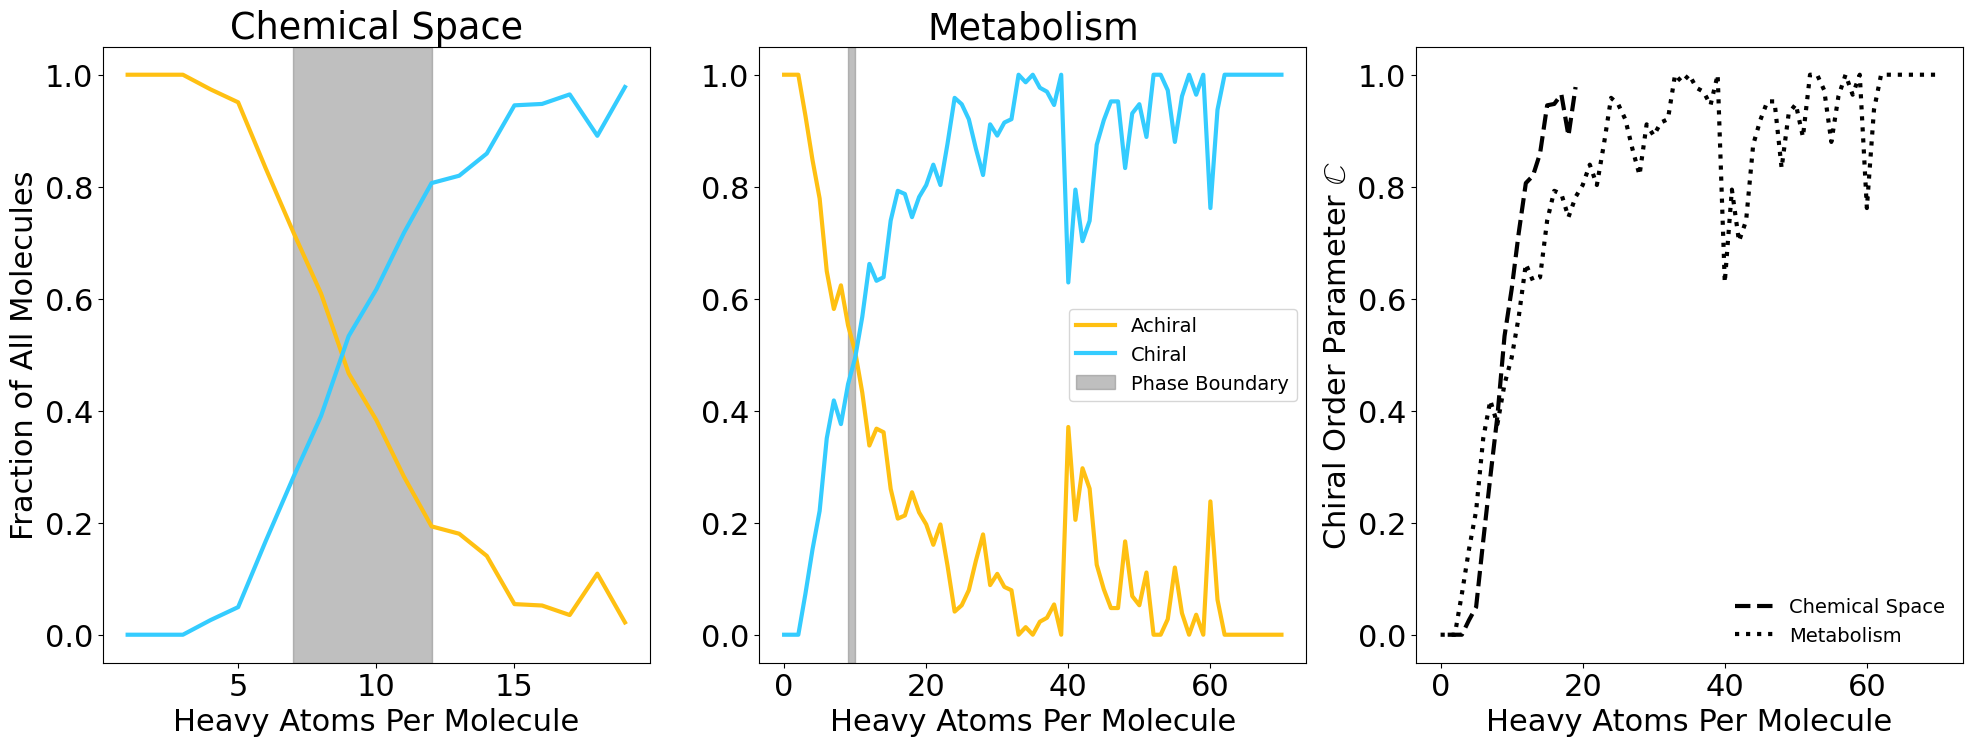

In [7]:
# fig_count = 2

plt.rcParams['figure.constrained_layout.use'] = False

plt.figure(figsize=(24, 8))

gs = gridspec.GridSpec(8, 6)

ax1 = plt.subplot(gs[:, 0:2])
ax1.plot(gdb_df["fraction_achiral"], linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(gdb_df["fraction_chiral"], linewidth=3, label="Chiral", color=chiral_color)
ax1.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

#ax1.set_xlim(0,16)
ax1.set_ylim(-0.05, 1.05)
ax1.set_xlabel("Heavy Atoms Per Molecule")
ax1.set_ylabel("Fraction of All Molecules")
ax1.set_title("Chemical Space")

ax2 = plt.subplot(gs[:, 2:4])
ax2.plot(1 - JGI_cop, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(JGI_cop, linewidth=3, label="Chiral", color=chiral_color)
ax2.axvspan(9, 10, alpha=0.5, color='grey', label="Phase Boundary")

ax2.legend(prop={"size": 14})

#ax2.set_xlim(0,16)
ax2.set_ylim(-0.05, 1.05)
ax2.set_xlabel("Heavy Atoms Per Molecule")
ax2.set_title("Metabolism")

ax3 = plt.subplot(gs[:, 4:])
ax3.plot(gdb_cop, linewidth=3, label="Chemical Space", color="k", linestyle="--")
ax3.plot(JGI_cop, linewidth=3, label="Metabolism", color="k", linestyle=":")

ax3.legend(frameon=False, prop={"size": 14})
#ax3.set_xlim(0,16)
ax3.set_ylim(-0.05, 1.05)
ax3.set_xlabel("Heavy Atoms Per Molecule")
ax3.set_ylabel(r"Chiral Order Parameter $\mathbb{C}$")
ax3.annotate(xy=(150, 0.4), text=r"$\mathbb{C} = \frac{C}{C+A}$", )

plt.subplots_adjust(wspace=0.5)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

# Network Expansion

## Primordial Expansions

In [8]:
from network_expansion import *

#Run network expansion processing
# Seed set
seed_name = "JM|G24|G17|TW"
rxn_db = reaction_file
max_generation = 1000  #Arbitrarily large 

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))

compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seed_sets = {
    i: seed_scope.query('Source.str.contains("' + i + '")').index
    for i in seed_groups
}
print(f"- Seed Set ({seed_name}) -")

### Run network expansion on original seed set
results = dict()
for name, seeds in seed_sets.items():
    print(seeds)
    results[name] = expand_from_seed_set(seeds=seeds,
                                         reactions=reaction_scope,
                                         max_gen=max_generation)
    results[name]['bipartite_edgelist'] = make_bipartite_edge_list(results[name]['edge_pool'])


### Process expansion (including chiral %s at each step & heavy atom count)

summaries = {
    'compound count':
        result_to_df(results, key='cps', to_apply=lambda x: x.sum()),
    'reaction count':
        result_to_df(results, key='rns', to_apply=lambda x: x.sum()),
    'chiral compound count':
        get_compound_chiral_count(results[seed_name]["cps"], keggC_df, chiral_flag=True),
    'achiral compound count':
        get_compound_chiral_count(results[seed_name]["cps"], keggC_df, chiral_flag=False),
    'chiral fraction':
        result_to_df(results, key='chiral_fraction', to_apply=lambda x: x),
    'chiral avg heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=True,
                                          calc="mean"),
    'achiral avg heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=False,
                                          calc="mean"),
    'chiral std heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=True,
                                          calc="std"),
    'achiral std heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=False,
                                          calc="std")
}

### Determines achiral/chiral crossover & first chiral compound
achiral_chiral_crossover_step = 0
first_chiral_step = 0
cum_chiral_count = summaries["chiral compound count"][0].to_list()
cum_achiral_count = summaries["achiral compound count"][0].to_list()
for i in range(len(summaries["chiral compound count"][0].to_list())):
    if cum_chiral_count[i] > 0 and first_chiral_step == 0:
        first_chiral_step = i
    if cum_chiral_count[i] > cum_achiral_count[
        i] and achiral_chiral_crossover_step == 0:
        achiral_chiral_crossover_step = i

print("- Chirality Statistics -")
print(f"\tAchiral To Chiral Crossover Step: {achiral_chiral_crossover_step}")
print(f"\tFirst Chiral Compound Appearance Step: {first_chiral_step}")
print(
    f"\tExpansion Size At First Chiral Compound Appearance: {summaries['compound count'].iloc[first_chiral_step][seed_name]} Compounds, {summaries['reaction count'].iloc[first_chiral_step][seed_name]} Reactions")
print(
    f"\tAverage Achiral Heavy Atoms At Crossover Step: {round(summaries['achiral avg heavy atoms'].iloc[achiral_chiral_crossover_step][0], 3)}")

- Seed Set (JM|G24|G17|TW) -
Index(['C00697', 'C00033', 'C00058', 'C00283', 'C00288', 'C00001', 'C00009',
       'C00011', 'C00014', 'C00080', 'C00059', 'C00022', 'C00026', 'C00028',
       'C00030', 'C00036', 'C00042', 'C00048', 'C00069', 'C00071', 'C00122',
       'C98944', 'C00161', 'C00175', 'C00205', 'C00209', 'C00282', 'C00305',
       'C98947', 'C00417', 'C01330', 'C01335', 'C01528', 'C01732', 'C06232',
       'C14818', 'C14819', 'C17023', 'C19609', 'C19806', 'C00027', 'C00488',
       'C00698', 'C01324', 'C01326', 'C01327', 'C01328', 'C05359', 'C98999',
       'C98924', 'C19610', 'C19611', 'C20396', 'C00067', 'C00111', 'C00708',
       'C01353', 'C05684'],
      dtype='object', name='Compound_id')
- Chirality Statistics -
	Achiral To Chiral Crossover Step: 5
	First Chiral Compound Appearance Step: 1
	Expansion Size At First Chiral Compound Appearance: 257 Compounds, 2351 Reactions
	Average Achiral Heavy Atoms At Crossover Step: 9.074


In [9]:
new_chiral_count = []
new_achiral_count = []
for i in range(len(cum_chiral_count)):
    if i > 0:
        new_chiral_count.append(cum_chiral_count[i] - cum_chiral_count[i - 1])
        new_achiral_count.append(cum_achiral_count[i] - cum_achiral_count[i - 1])
    else:
        new_chiral_count.append(0)
        new_achiral_count.append(0)

new_total_count = [x + y for x, y in zip(new_chiral_count, new_achiral_count)]

In [10]:
chiral_color = "#34CCFF"
achiral_color = "#FFC012"
sum_color = "limegreen"

Final chiral count: 6230
Final achiral count: 2903


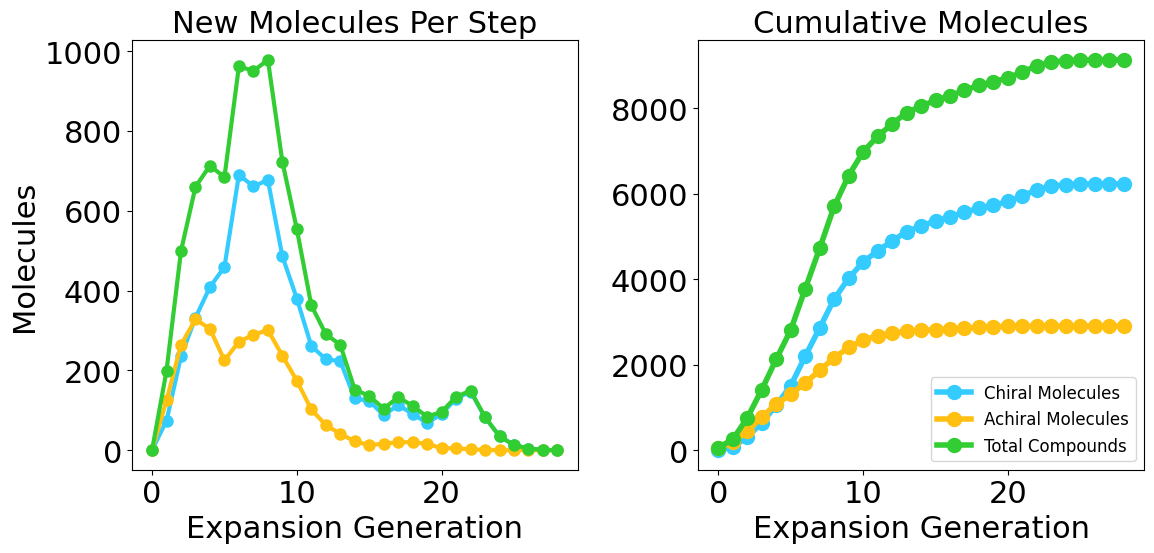

In [11]:
# fig_count = 3

### Primordial Expansion plots
plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(1, 2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0, 0])

ax1.plot(new_chiral_count, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Molecules", )
ax1.plot(new_achiral_count, color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Molecules")
ax1.plot(np.arange(0, len(new_chiral_count), 1), new_total_count,
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Compounds")

#ax1.legend(facecolor="white", prop={"size": 12})
ax1.set_xlabel("Expansion Generation", fontsize=22)
ax1.set_ylabel("Molecules", fontsize=22)
ax1.set_title("New Molecules Per Step", fontsize=22)

#Cumulative plot
print(f"Final chiral count: {cum_chiral_count[-1]}")
print(f"Final achiral count: {cum_achiral_count[-1]}")

ax2 = plt.subplot(gs[0, 1])
ax2.plot(cum_chiral_count, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Molecules", )
ax2.plot(cum_achiral_count, color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Molecules")
ax2.plot(np.arange(0, len(cum_chiral_count), 1), summaries["compound count"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Compounds")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Expansion Generation", fontsize=22)
# ax2.set_ylabel("Cumulative Molecules", fontsize=22)
ax2.set_title("Cumulative Molecules", fontsize=22)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

### Network figure

Squares, all steps

In [12]:
### Network figure
result_network = generate_annotated_bipartite_edge_list(results[seed_name])
transition_edge_df = result_network['bipartite_edgelist'].query('step <= 100').copy(
    deep=True)  #Arbitrary 100 to ensure all cpds are graphed
networks = {i: nx.from_pandas_edgelist(transition_edge_df[transition_edge_df[i]],
                                       source='source', target='target', edge_attr=True, create_using=nx.DiGraph())
            for i in ['impactful_precursor', 'immediate_precursor', 'directed']}
compound_nodes = {i: set(j.nodes()).difference(reaction_scope.index) for i, j in networks.items()}
networks_uni = {i: bipartite.projected_graph(networks[i], nodes=compound_nodes[i]) for i in networks.keys()}

attributes = pd.read_csv(compound_file,
                         index_col=0)
attributes.drop(labels=["smiles", "formula", "molecular_weight", "n_heavy_atoms"], axis=1,
                inplace=True)
attributes["is_chiral"] = attributes['n_chiral_centers'].map(lambda x: x > 0)
attributes['is_chiral_color'] = attributes['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF")

steps = []
for index, _ in attributes.iterrows():
    step = 0
    step_found = False
    for new_cpds in results[seed_name]["participants"]["new compounds"]:
        if index in new_cpds:
            steps.append(step)
            step_found = True
        step += 1
    if not step_found:
        steps.append(np.nan)

attributes['gen'] = steps
gen_color = 'Greys'
attributes['gen_color'] = colorize_series(attributes['gen'], cmap=gen_color).tolist()

In [13]:
show = 'impactful_precursor'
rotate = False

G1 = networks_uni[show]  #using impactful_precursor from network generation
#Remove G nodes that are not in attributes df
nodes_to_keep = attributes.index.to_list()
nodes_to_remove = [n for n in nodes_to_keep if n not in G1.nodes()]
G1.remove_nodes_from(nodes_to_remove)

nx.set_node_attributes(G1, attributes['is_chiral_color'], 'is_chiral_color')
layers = [list(i) for i in attributes.loc[list(G1.nodes())].groupby(by='gen').groups.values()]
pos = get_multipartite_layout(edges=list(G1.edges), layers=layers, reduce_edge_crossings=True,
                              uniform_node_spacing=True, layer_positions=np.arange(1, len(layers), 1 / len(layers)))
#for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0] + 0.2) ** 2  # spread out later gens to reduce extreme angles 
if rotate: pos = {i: j[::-1] for i, j in pos.items()}

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/netgraph/_node_layout.py:1383: UserWarning: Some layer positions are outside the bounding box defined by `origin` and `scale`.
  warnings.warn("Some layer positions are outside the bounding box defined by `origin` and `scale`.")


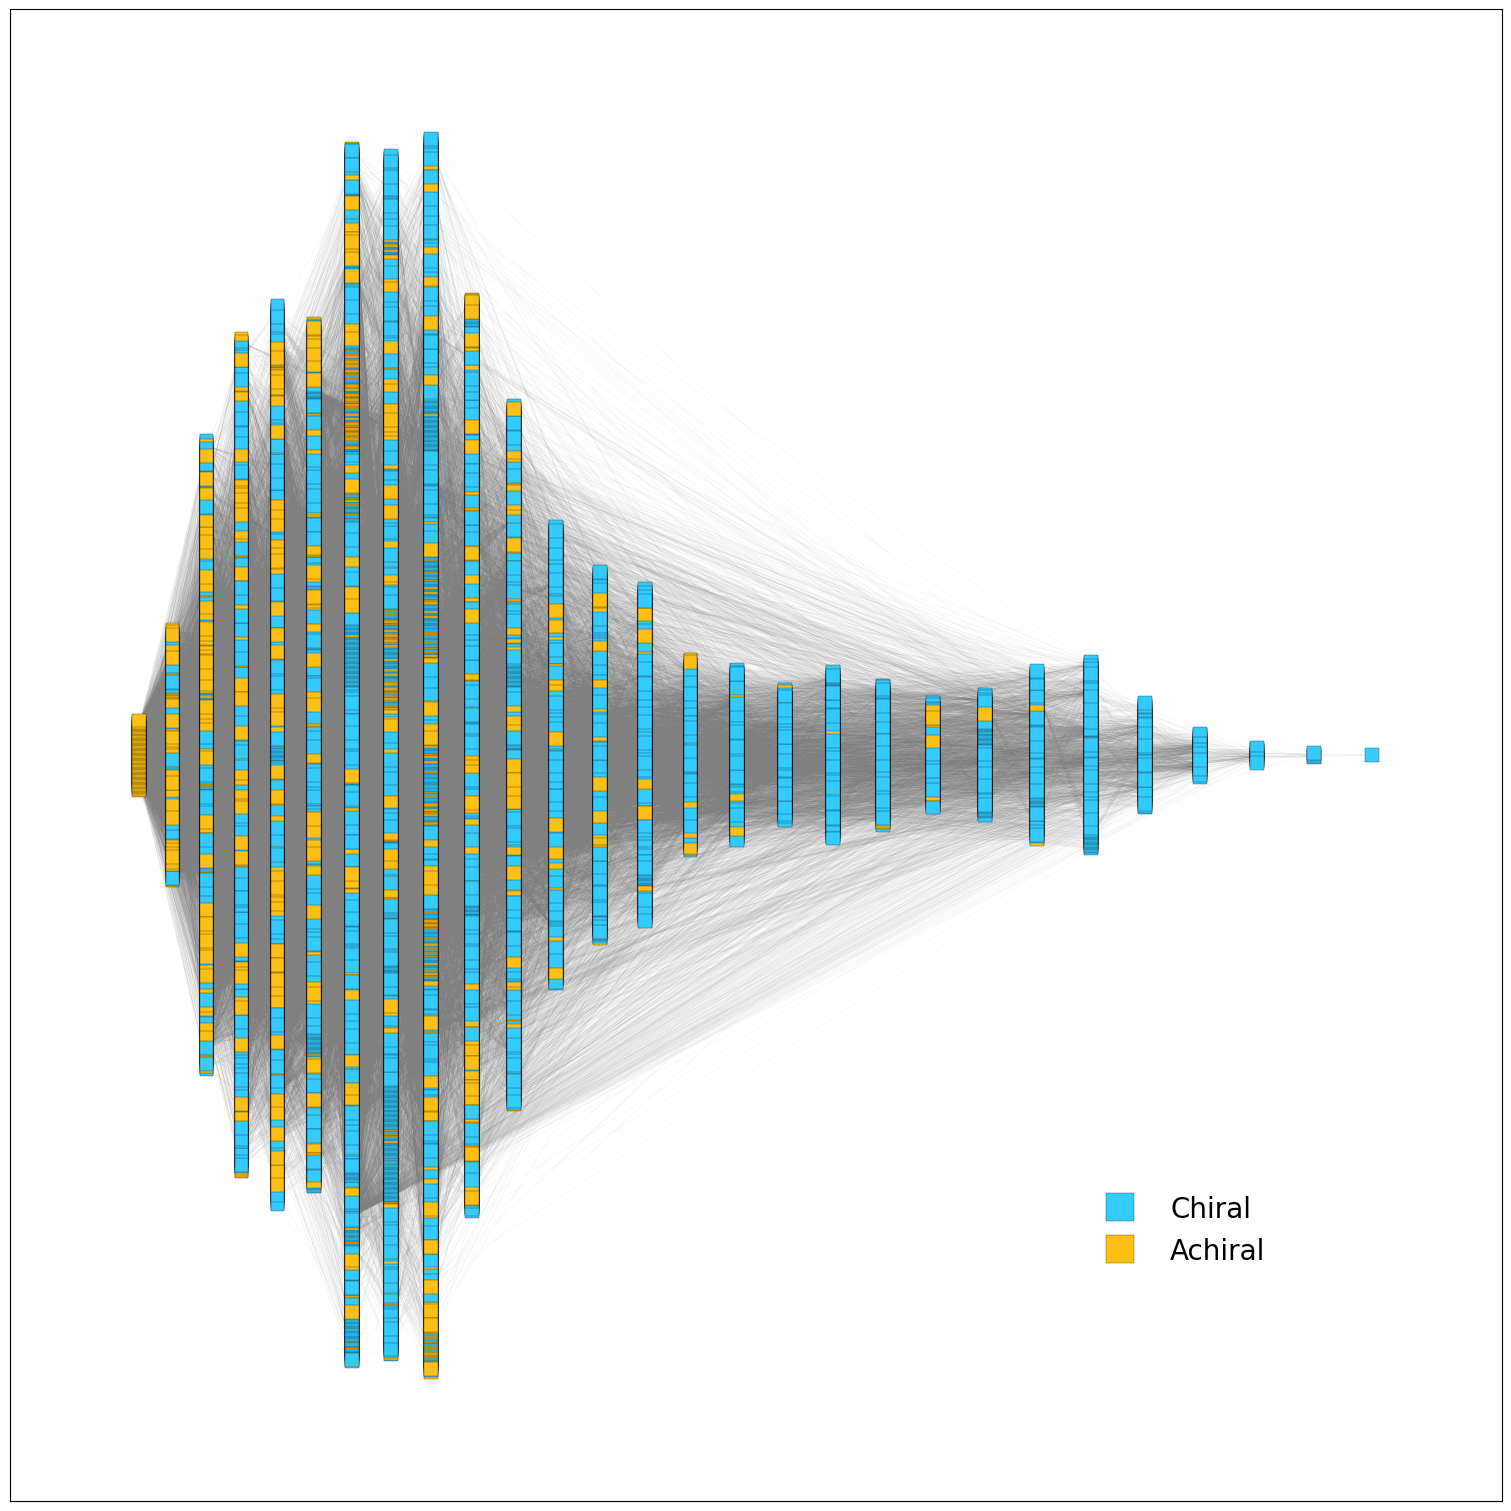

In [14]:
# fig_count = 4

fig, ax = plt.subplots(figsize=(15, 15), layout='constrained')
nx.draw_networkx(G1.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5, 0.5, 0.5, 0.5],
                 node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()),
                 edgecolors='k', width=0.03, arrows=False,
                 linewidths=0.2, node_size=100, node_shape='s', alpha=0.99,
                 with_labels=False)

plt.legend(loc='lower right', borderpad=8, frameon=False, handles=[
    plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF',
               markersize=20, label='Chiral'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2,
               markersize=20, label='Achiral')], prop={'size': 20})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

## Random Seed Set Expansions

In [15]:
# chiral_color = "#34CCFF"
# achiral_color = "#FFC012"
# mixed_color = "green"

# ### Get X random seed sets, both chiral & achiral
# n_iter = 100
# min_ss_size = 2
# max_ss_size = 10
# ss_sizes = [2, 3, 4, 5, 10, 20, 50, 100]

# randAchiral_results = dict()
# randChiral_results = dict()
# random_achiral_seeds = dict()
# random_chiral_seeds = dict()
# # for random_ss_size in range(min_ss_size, max_ss_size+1):
# for random_ss_size in ss_sizes:
#     for i in range(n_iter):
#         random_achiral_seeds[f"Random_{random_ss_size}_{i}"] = get_random_seed_set(
#             keggC_df, random_ss_size, chirality="achiral", random_state=i)
#         random_chiral_seeds[f"Random_{random_ss_size}_{i}"] = get_random_seed_set(
#             keggC_df, random_ss_size, chirality="chiral", random_state=i)

# # print(f"- Expanding {n_iter*(max_ss_size-min_ss_size+1)} Achiral Seed Sets -")
# print(f"- Expanding {n_iter * len(ss_sizes)} Achiral Seed Sets -")

# achiral_full_chiral_CpdCount = list()
# achiral_full_achiral_CpdCount = list()
# achiral_full_RxnCount = list()
# for name, seeds in tqdm(random_achiral_seeds.items(), total=n_iter * len(ss_sizes)):  #(max_ss_size-min_ss_size+1)):
#     randAchiral_results = expand_from_seed_set(
#         seeds=seeds, reactions=reaction_scope, max_gen=max_generation)    
#     ### Process expansion (including chiral %s at each step & heavy atom count)
#     achiral_full_chiral_CpdCount.append(
#         get_compound_chiral_count(randAchiral_results["cps"], keggC_df, chiral_flag=True)[0].to_list())
#     achiral_full_achiral_CpdCount.append(
#         get_compound_chiral_count(randAchiral_results["cps"], keggC_df, chiral_flag=False)[0].to_list())

#     summaries = {
#         'reaction count': {"rns": len(randAchiral_results["rns"])}
#     }
#             # result_to_df(randAchiral_results, key='rns', to_apply=lambda x: x.sum()),
#     # }
#     achiral_full_RxnCount.append(summaries["reaction count"]['rns'])
    
# pickle.dump(achiral_full_chiral_CpdCount, open("../Data/RandomSeedSets_SIAchiralFullChiralCpdCount.pkl", "wb"))
# pickle.dump(achiral_full_achiral_CpdCount, open("../Data/RandomSeedSets_SIAchiralFullAchiralCpdCount.pkl", "wb"))
# pickle.dump(achiral_full_RxnCount, open("../Data/RandomSeedSets_SIAchiralFullRxnCount.pkl", "wb"))

# print(f"- Expanding {n_iter * len(ss_sizes)} Chiral Seed Sets -")
# chiral_full_chiral_CpdCount = list()
# chiral_full_achiral_CpdCount = list()
# chiral_full_RxnCount = list()
# for name, seeds in tqdm(random_chiral_seeds.items(), total=n_iter * len(ss_sizes)):
#     randChiral_results = expand_from_seed_set(
#         seeds=seeds, reactions=reaction_scope, max_gen=max_generation)

#     chiral_full_chiral_CpdCount.append(
#         get_compound_chiral_count(randChiral_results["cps"], keggC_df, chiral_flag=True)[0].to_list())
#     chiral_full_achiral_CpdCount.append(
#         get_compound_chiral_count(randChiral_results["cps"], keggC_df, chiral_flag=False)[0].to_list())
#     summaries = {
#         'reaction count': {"rns": len(randAchiral_results["rns"])}
#     }
#     chiral_full_RxnCount.append(summaries["reaction count"]['rns'])

# pickle.dump(chiral_full_chiral_CpdCount, open("../Data/RandomSeedSets_SIChiralFullChiralCpdCount.pkl", "wb"))
# pickle.dump(chiral_full_achiral_CpdCount, open("../Data/RandomSeedSets_SIChiralFullAchiralCpdCount.pkl", "wb"))
# pickle.dump(chiral_full_RxnCount, open("../Data/RandomSeedSets_SIChiralFullRxnCount.pkl", "wb"))

In [16]:
achiral_full_chiral_CpdCount = pickle.load(open("../Data/RandomSeedSets_SIAchiralFullChiralCpdCount.pkl", "rb"))
achiral_full_achiral_CpdCount = pickle.load(open("../Data/RandomSeedSets_SIAchiralFullAchiralCpdCount.pkl", "rb"))
achiral_full_RxnCount = pickle.load(open("../Data/RandomSeedSets_SIAchiralFullRxnCount.pkl", "rb"))

chiral_full_chiral_CpdCount = pickle.load(open("../Data/RandomSeedSets_SIChiralFullChiralCpdCount.pkl", "rb"))
chiral_full_achiral_CpdCount = pickle.load(open("../Data/RandomSeedSets_SIChiralFullAchiralCpdCount.pkl", "rb"))
chiral_full_RxnCount = pickle.load(open("../Data/RandomSeedSets_SIChiralFullRxnCount.pkl", "rb"))

In [17]:
# Testing affect of various seed set sizes on expansion scopes
ss_sizes = [2, 3, 4, 5, 10, 20, 50, 100]
n_iter = 100

chiral_avg_cpd_scope = list()
achiral_avg_cpd_scope = list()
chiral_avg_rxn_scope = list()
achiral_avg_rxn_scope = list()

full_chiral_scope = list()
full_achiral_scope = list()

print(chiral_full_RxnCount)
offset = 0
for random_ss_size in ss_sizes:  # range(min_ss_size, max_ss_size+1):
    chiral_cpd_scope = list()
    achiral_cpd_scope = list()
    chiral_rxn_scope = list()
    achiral_rxn_scope = list()
    for i in range(n_iter):
        chiral_cpd_scope.append(
            chiral_full_chiral_CpdCount[i + offset][-1] + chiral_full_achiral_CpdCount[i + offset][-1])
        achiral_cpd_scope.append(
            achiral_full_chiral_CpdCount[i + offset][-1] + achiral_full_achiral_CpdCount[i + offset][-1])
        chiral_rxn_scope.append(chiral_full_RxnCount[i + offset])
        achiral_rxn_scope.append(achiral_full_RxnCount[i + offset])

    full_chiral_scope.extend(chiral_cpd_scope)
    full_achiral_scope.extend(achiral_cpd_scope)

    chiral_avg_cpd_scope.append(np.mean(chiral_cpd_scope))
    achiral_avg_cpd_scope.append(np.mean(achiral_cpd_scope))
    chiral_avg_rxn_scope.append(np.mean(chiral_rxn_scope))
    achiral_avg_rxn_scope.append(np.mean(achiral_rxn_scope))

    offset += n_iter


[118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449, 118449,

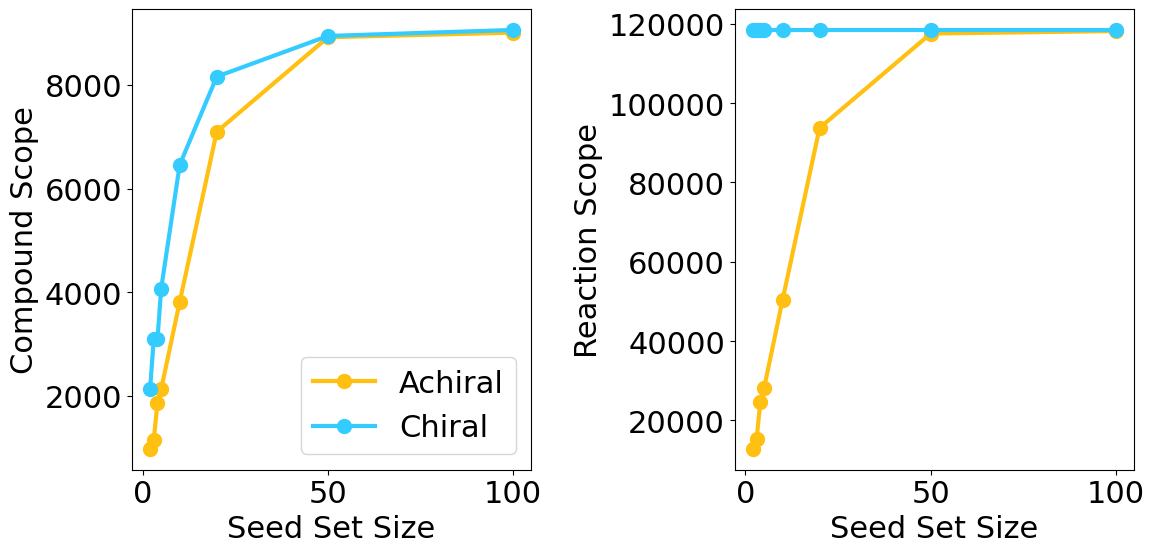

In [18]:
# fig_count = 5

plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(1, 2)

## Cpd scope
ax1 = plt.subplot(gs[0, 0])
# ax1.plot(np.arange(min_ss_size,max_ss_size+1,1), achiral_avg_cpd_scope, color=achiral_color, label="achiral", 
#          marker="o", linewidth=3, markersize=10)
# ax1.plot(np.arange(min_ss_size,max_ss_size+1,1), chiral_avg_cpd_scope, color=chiral_color, label="chiral", 
#          marker="o", linewidth=3, markersize=10)
ax1.plot(ss_sizes, achiral_avg_cpd_scope, color=achiral_color, label="Achiral",
         marker="o", linewidth=3, markersize=10)
ax1.plot(ss_sizes, chiral_avg_cpd_scope, color=chiral_color, label="Chiral",
         marker="o", linewidth=3, markersize=10)

ax1.legend()
ax1.set_xlabel("Seed Set Size")
ax1.set_ylabel("Compound Scope")

## Rxn scope
ax2 = plt.subplot(gs[0, 1])
# ax2.plot(np.arange(min_ss_size,max_ss_size+1,1), achiral_avg_rxn_scope, color=achiral_color, label="achiral", 
#          marker="o", linewidth=3, markersize=10)
# ax2.plot(np.arange(min_ss_size,max_ss_size+1,1), chiral_avg_rxn_scope, color=chiral_color, label="chiral", 
#          marker="o", linewidth=3, markersize=10)
ax2.plot(ss_sizes, achiral_avg_rxn_scope, color=achiral_color, label="Achiral",
         marker="o", linewidth=3, markersize=10)
ax2.plot(ss_sizes, chiral_avg_rxn_scope, color=chiral_color, label="Chiral",
         marker="o", linewidth=3, markersize=10)

ax2.set_xlabel("Seed Set Size")
ax2.set_ylabel("Reaction Scope")

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")

fig_count += 1

In [19]:
def alternative_ridgeline_plot(full_chiral_cpdCount, full_achiral_CpdCount, label, n_iter, color):
    df_ridgeline = pd.DataFrame(columns=["n", "c"])

    sizes = []
    labels = []
    offset = 0
    for random_ss_size in ss_sizes:
        for i in range(n_iter):
            sizes.append(full_chiral_cpdCount[i + offset][-1] + full_achiral_CpdCount[i + offset][-1])
            labels.append(random_ss_size)
        offset += n_iter

    df_ridgeline["n"] = sizes
    df_ridgeline["c"] = labels

    #find the log of each expansion
    df_ridgeline["n"] = pd.to_numeric(df_ridgeline["n"], errors="coerce")

    plt.figure(figsize=(10, 25))
    gs = gridspec.GridSpec(len(ss_sizes), 1)  #Have nrows dependant on number of seed set sizes

    ## Cpd scope
    for i in range(len(ss_sizes)):
        ax = plt.subplot(gs[i, 0])

        if i == 0:
            ax.set_title(f"{label}-Only Expansions")

        data = np.array(df_ridgeline[df_ridgeline["c"] == ss_sizes[i]]["n"].to_list()).astype(np.int64)

        sns.kdeplot(data, clip_on=True, fill=False, alpha=1, lw=1.5, bw_method=.2, ax=ax, color=color,
                    label=f"Seed Set Size: {ss_sizes[i]}")

        ax.legend()
        if np.min(data) < 100:
            ax.set_xlim(0, np.max(data))
        else:
            ax.set_xlim(np.min(data), np.max(data))

    # plt.title()
    ax.set_xlabel("Expansion Scope")

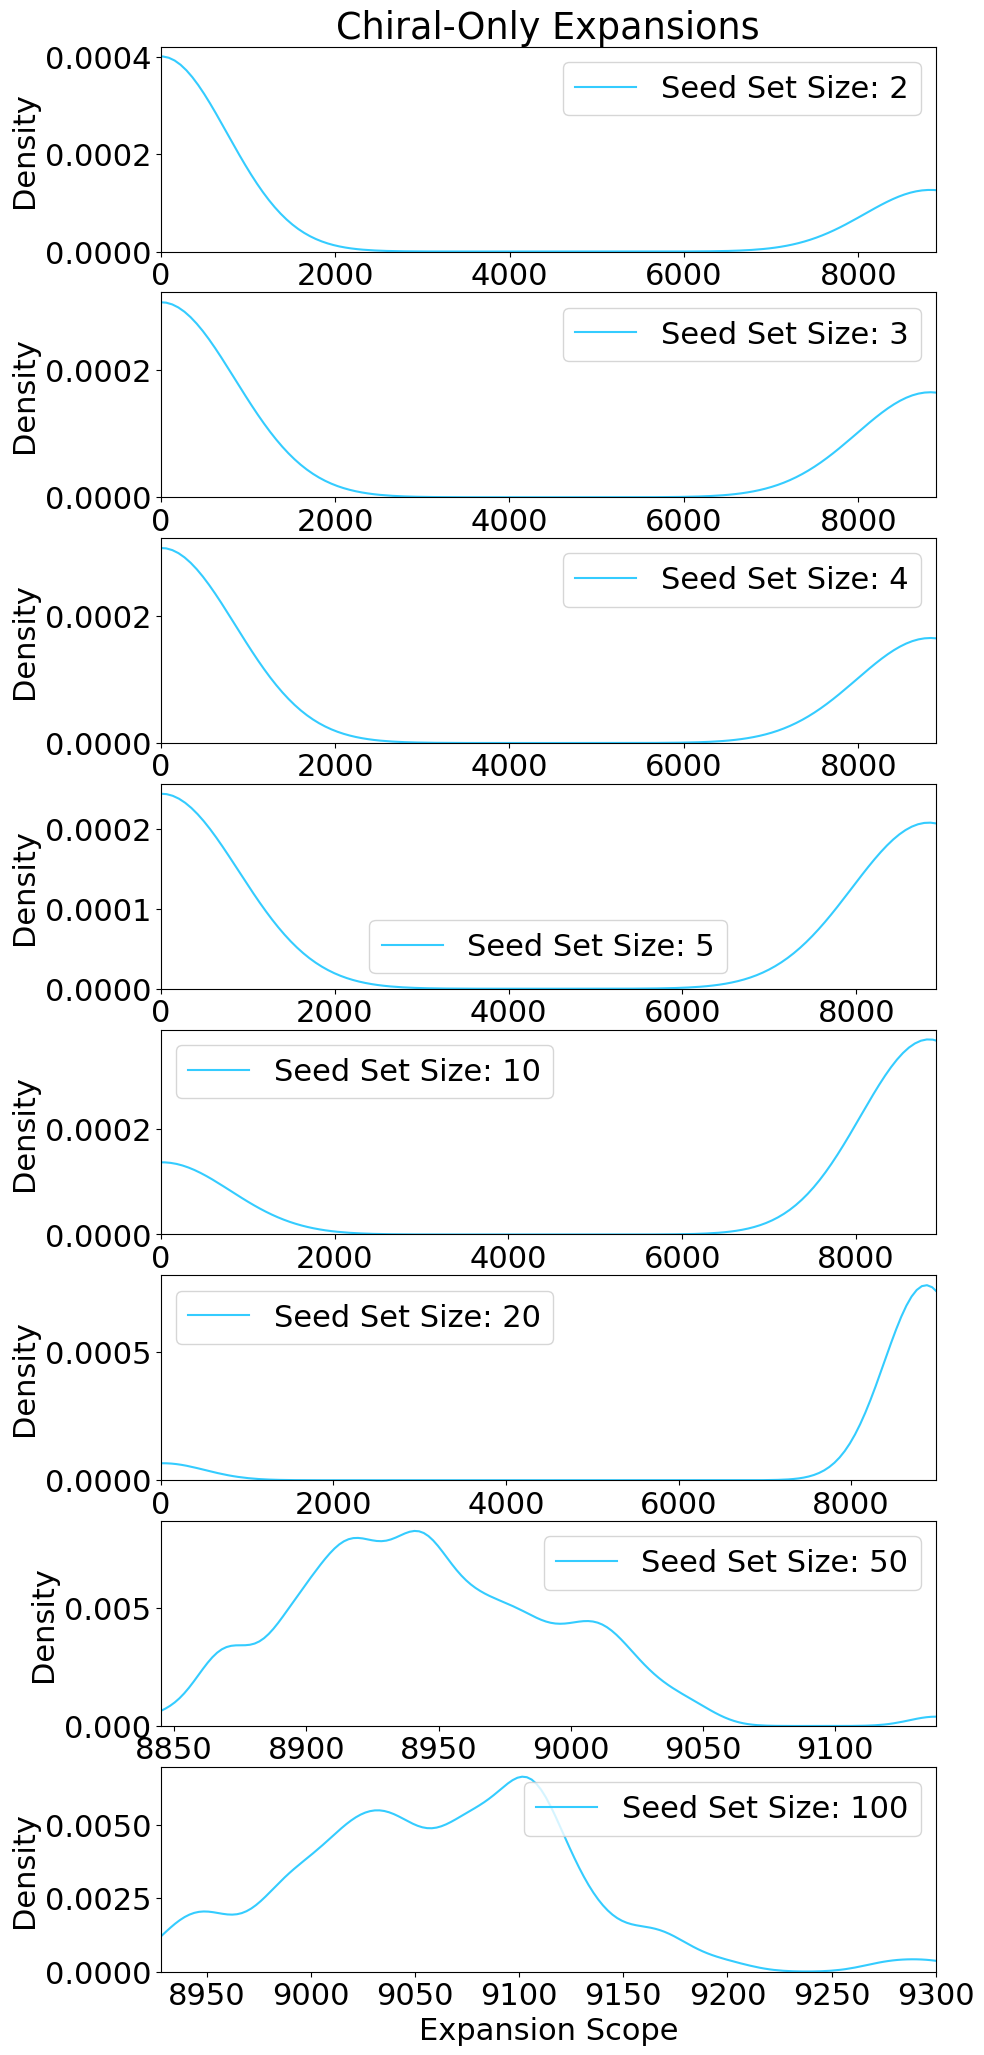

In [20]:
# print(n_iter)
# print(chiral_full_chiral_CpdCount)
# print(chiral_full_achiral_CpdCount)
# print(len(chiral_full_achiral_CpdCount))
# fig_count = 6
gs = gridspec.GridSpec(1, 2)
alternative_ridgeline_plot(chiral_full_chiral_CpdCount, chiral_full_achiral_CpdCount, "Chiral", n_iter, chiral_color)

plt.savefig(f"{fig_path}{fig_count}a.svg", format="svg") #Two parts of figure 6

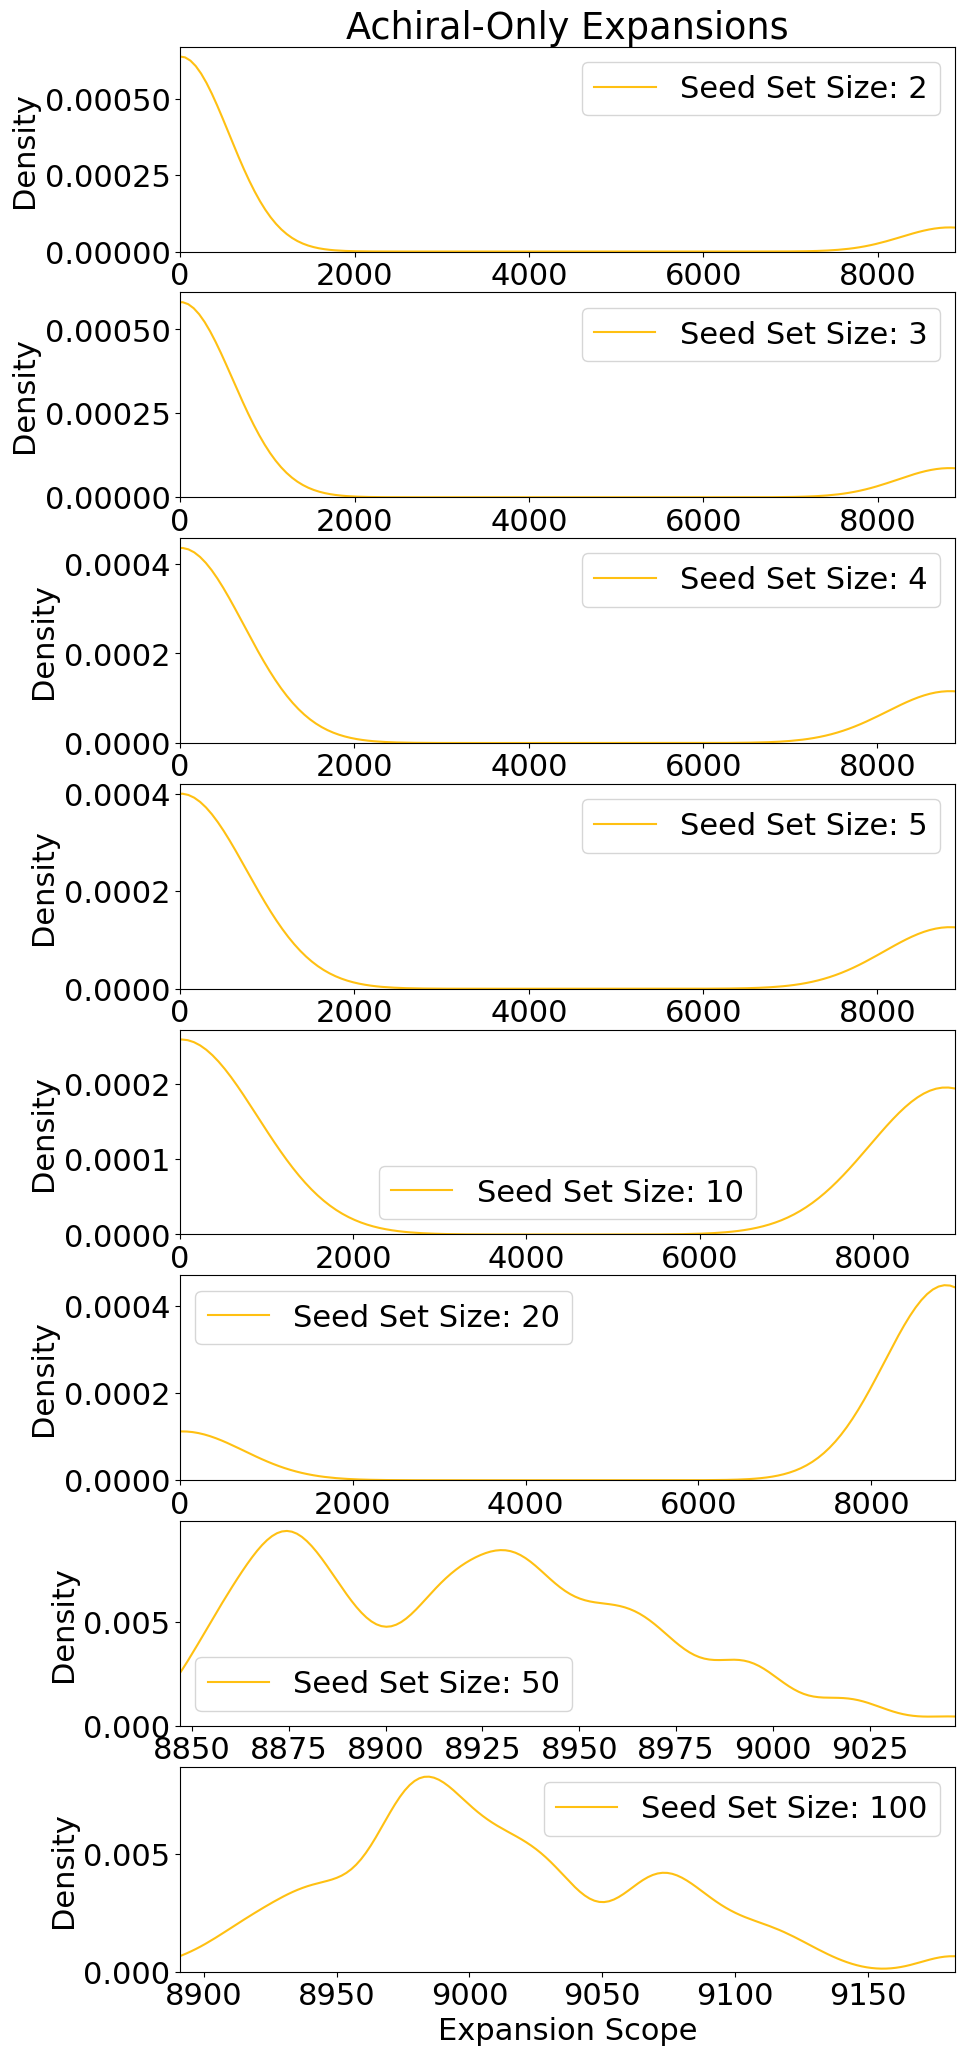

In [21]:
# fig_count = 6
alternative_ridgeline_plot(achiral_full_chiral_CpdCount, achiral_full_achiral_CpdCount, "Achiral", n_iter,
                           achiral_color)

plt.savefig(f"{fig_path}{fig_count}b.svg", format="svg") #Two parts of SI Figure 6
fig_count += 1

### Scope Histogram

Histogram showing expansion scopes put together (separated by chiral/achiral, but otherwise alltogether)

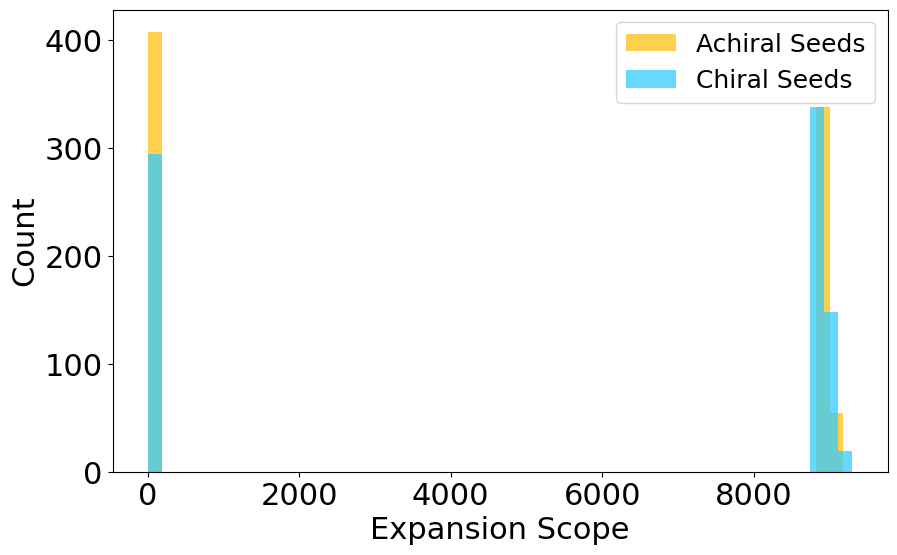

In [22]:
# fig_count = 7
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(full_achiral_scope, bins=50, color=achiral_color, label="Achiral Seeds", alpha=0.75)
ax.hist(full_chiral_scope, bins=50, color=chiral_color, label="Chiral Seeds", alpha=0.75)

# ax.set_yscale("log")
ax.set_xlabel("Expansion Scope", fontsize=22)
ax.set_ylabel("Count", fontsize=22)
ax.tick_params(axis='both', which='both', labelsize=22)

plt.legend(facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
plt.show()
fig_count += 1

## Full Seed Set Permutations

Permute the seed set in a few ways:
- 20% dropout (1000 iterations)
- Size (drop increasing numbers of heavy atoms)

And get the following results:
- avg chiral order parameter at each step (similar to random expansions in manuscript)
- scope
- chiral/achiral crossover 

In [24]:
seed_name = "JM|G24|G17|TW"
rxn_db = reaction_file
max_generation = 1000  #Arbitrarily large 
n_iter = 100

dropout_chiral_count = list()
dropout_achiral_count = list()
sizefilter_chiral_count = list()
sizefilter_achiral_count = list()

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))
compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seed_sets = {
        i: seed_scope.query('Source.str.contains("' + i + '")').index
        for i in seed_groups
    }
total_seeds = len(seed_sets[seed_name])
keep_percent = 0.8

print("-- Dropout Expansions --")
# for i in tqdm(range(n_iter)):
#     ### Keeping 80% of seed set
#     seed_sets = {
#         i: seed_scope.query('Source.str.contains("' + i + '")').sample(math.floor(total_seeds*keep_percent)).index
#         for i in seed_groups
#     }
#     for name, seeds in seed_sets.items():
#         randAchiral_results = expand_from_seed_set(
#             seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
#         dropout_chiral_count.append(
#             get_compound_chiral_count(randAchiral_results["cps"], keggC_df, chiral_flag=True)[0].to_list())
#         dropout_achiral_count.append(
#             get_compound_chiral_count(randAchiral_results["cps"], keggC_df, chiral_flag=False)[0].to_list())

# pickle.dump(randAchiral_results, open("../Data/DropoutResults_SIChiralFullChiralCpdCount.pkl", "wb"))
# pickle.dump(dropout_chiral_count, open("../Data/DropoutChiralCounts_SIChiralFullAchiralCpdCount.pkl", "wb"))
# pickle.dump(dropout_achiral_count, open("../Data/DropoutAchiralCounts_SIChiralFullRxnCount.pkl", "wb"))

randAchiral_results = pickle.load(open("../Data/DropoutResults_SIChiralFullChiralCpdCount.pkl", "rb"))
dropout_chiral_count = pickle.load(open("../Data/DropoutChiralCounts_SIChiralFullAchiralCpdCount.pkl", "rb"))
dropout_achiral_count = pickle.load(open("../Data/DropoutAchiralCounts_SIChiralFullRxnCount.pkl", "rb"))

seed_scope = seed_scope.join(keggC_df.set_index('compound_id'))
seed_scope = seed_scope[seed_scope["Source"] != "LUCA"]  #Remove LUCA from heavy atom filtering
seed_scope.index.names = ['compound_id']
unique_heavy_atoms = list(set(seed_scope["n_heavy_atoms"]))
unique_heavy_atoms.reverse()
unique_heavy_atoms_seedSetSize = []
print("-- Heavy Atom Filter Expansions --")
for heavy_atom in unique_heavy_atoms:
    if heavy_atom > 0:
        print(f"- Expanding seeds with less than {heavy_atom} heavy atoms -")
        seed_scope_filtered = seed_scope[seed_scope["n_heavy_atoms"] < heavy_atom]
        seed_sets = {
            i: seed_scope_filtered.query('Source.str.contains("' + i + '")').index
            for i in seed_groups
        }
        for name, seeds in seed_sets.items():
            print(f"\tN Seeds: {len(seeds)}")
            unique_heavy_atoms_seedSetSize.append(len(seeds))
            heavyAtomSampling_results = expand_from_seed_set(
                seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
            sizefilter_chiral_count.append(
                get_compound_chiral_count(heavyAtomSampling_results["cps"], keggC_df, chiral_flag=True)[0].to_list())
            sizefilter_achiral_count.append(
                get_compound_chiral_count(heavyAtomSampling_results["cps"], keggC_df, chiral_flag=False)[0].to_list())


-- Dropout Expansions --
-- Heavy Atom Filter Expansions --
- Expanding seeds with less than 12 heavy atoms -
	N Seeds: 56
- Expanding seeds with less than 10 heavy atoms -
	N Seeds: 54
- Expanding seeds with less than 9 heavy atoms -
	N Seeds: 52
- Expanding seeds with less than 8 heavy atoms -
	N Seeds: 50
- Expanding seeds with less than 7 heavy atoms -
	N Seeds: 48
- Expanding seeds with less than 6 heavy atoms -
	N Seeds: 46
- Expanding seeds with less than 5 heavy atoms -
	N Seeds: 39
- Expanding seeds with less than 4 heavy atoms -
	N Seeds: 35
- Expanding seeds with less than 3 heavy atoms -
	N Seeds: 32
- Expanding seeds with less than 2 heavy atoms -
	N Seeds: 26
- Expanding seeds with less than 1 heavy atoms -
	N Seeds: 6


In [25]:
dropout_chiralPercentage = []
dropout_avg_percentages_chiral = []
dropout_std_percentages_chiral = []
dropout_scopes = []
dropout_crossover_steps = []

sizefilter_chiralPercentage = []
sizefilter_avg_percentages_chiral = []
sizefilter_std_percentages_chiral = []
sizefilter_scopes = []
sizefilter_crossover_steps = []
sizefilter_seedSizes = []

# Scopes
for i in range(len(dropout_chiral_count)):
    dropout_scopes.append(dropout_chiral_count[i][-1] + dropout_achiral_count[i][-1])

for i in range(len(sizefilter_chiral_count)):
    sizefilter_scopes.append(sizefilter_chiral_count[i][-1] + sizefilter_achiral_count[i][-1])

print(f"Dropout Scope Stats\n\tAverage: {round(np.mean(dropout_scopes), 3)}\n\tStd: {round(np.std(dropout_scopes), 3)}")
print(
    f"Size Filter Scope Stats\n\tAverage: {round(np.mean(sizefilter_scopes), 3)}\n\tStd: {round(np.std(sizefilter_scopes), 3)}")

for i in range(len(dropout_chiral_count)):
    dropout_chiralPercentage.append(
        get_chiral_percentage(np.cumsum(dropout_chiral_count[i]),
                              np.cumsum(dropout_achiral_count[i])))

for i in range(len(sizefilter_chiral_count)):
    sizefilter_chiralPercentage.append(
        get_chiral_percentage(np.cumsum(sizefilter_chiral_count[i]),
                              np.cumsum(sizefilter_achiral_count[i])))

for i in range(len(dropout_chiral_count)):
    chiral_cumcpd_count = list(np.cumsum(dropout_chiral_count[i]))
    achiral_cumcpd_count = list(np.cumsum(dropout_achiral_count[i]))

    for j in range(len(chiral_cumcpd_count)):
        if chiral_cumcpd_count[j] >= achiral_cumcpd_count[j]:
            dropout_crossover_steps.append(j)
            break

for i in range(len(sizefilter_chiral_count)):
    chiral_cumcpd_count = list(np.cumsum(sizefilter_chiral_count[i]))
    achiral_cumcpd_count = list(np.cumsum(sizefilter_achiral_count[i]))

    for j in range(len(chiral_cumcpd_count)):
        if chiral_cumcpd_count[j] >= achiral_cumcpd_count[j]:
            sizefilter_crossover_steps.append(j)
            break

print(
    f"Dropout Crossover Stats\n\tAverage: {round(np.mean(dropout_crossover_steps), 3)}\n\tStd: {round(np.std(dropout_crossover_steps), 3)}")
print(
    f"Size Filter Crossover Stats\n\tAverage: {round(np.mean(sizefilter_crossover_steps), 3)}\n\tStd: {round(np.std(sizefilter_crossover_steps), 3)}")

# Chiral percentages
for i in range(max_generation):
    percentages = []
    for result in dropout_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])
    dropout_avg_percentages_chiral.append(np.mean(percentages))
    dropout_std_percentages_chiral.append(np.std(percentages))

for i in range(max_generation):
    percentages = []
    for result in sizefilter_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])
    sizefilter_avg_percentages_chiral.append(np.mean(percentages))
    sizefilter_std_percentages_chiral.append(np.std(percentages))

for i in range(len(sizefilter_chiral_count)):
    sizefilter_seedSizes.append(sizefilter_chiral_count[i][0] + sizefilter_achiral_count[i][0])

### Original Expansion
original_percent_chiral = []
for i in range(len(cum_chiral_count)):
    original_percent_chiral.append(cum_chiral_count[i] / (cum_chiral_count[i] + cum_achiral_count[i]))

Dropout Scope Stats
	Average: 9103.26
	Std: 33.95
Size Filter Scope Stats
	Average: 8302.909
	Std: 2623.713
Dropout Crossover Stats
	Average: 6.08
	Std: 0.744
Size Filter Crossover Stats
	Average: 7.1
	Std: 1.136


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/_core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in scalar

<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/3742342882.py:24: SyntaxWarning: invalid escape sequence '\m'
  label="Original Expansion $\mathbb{C}$")


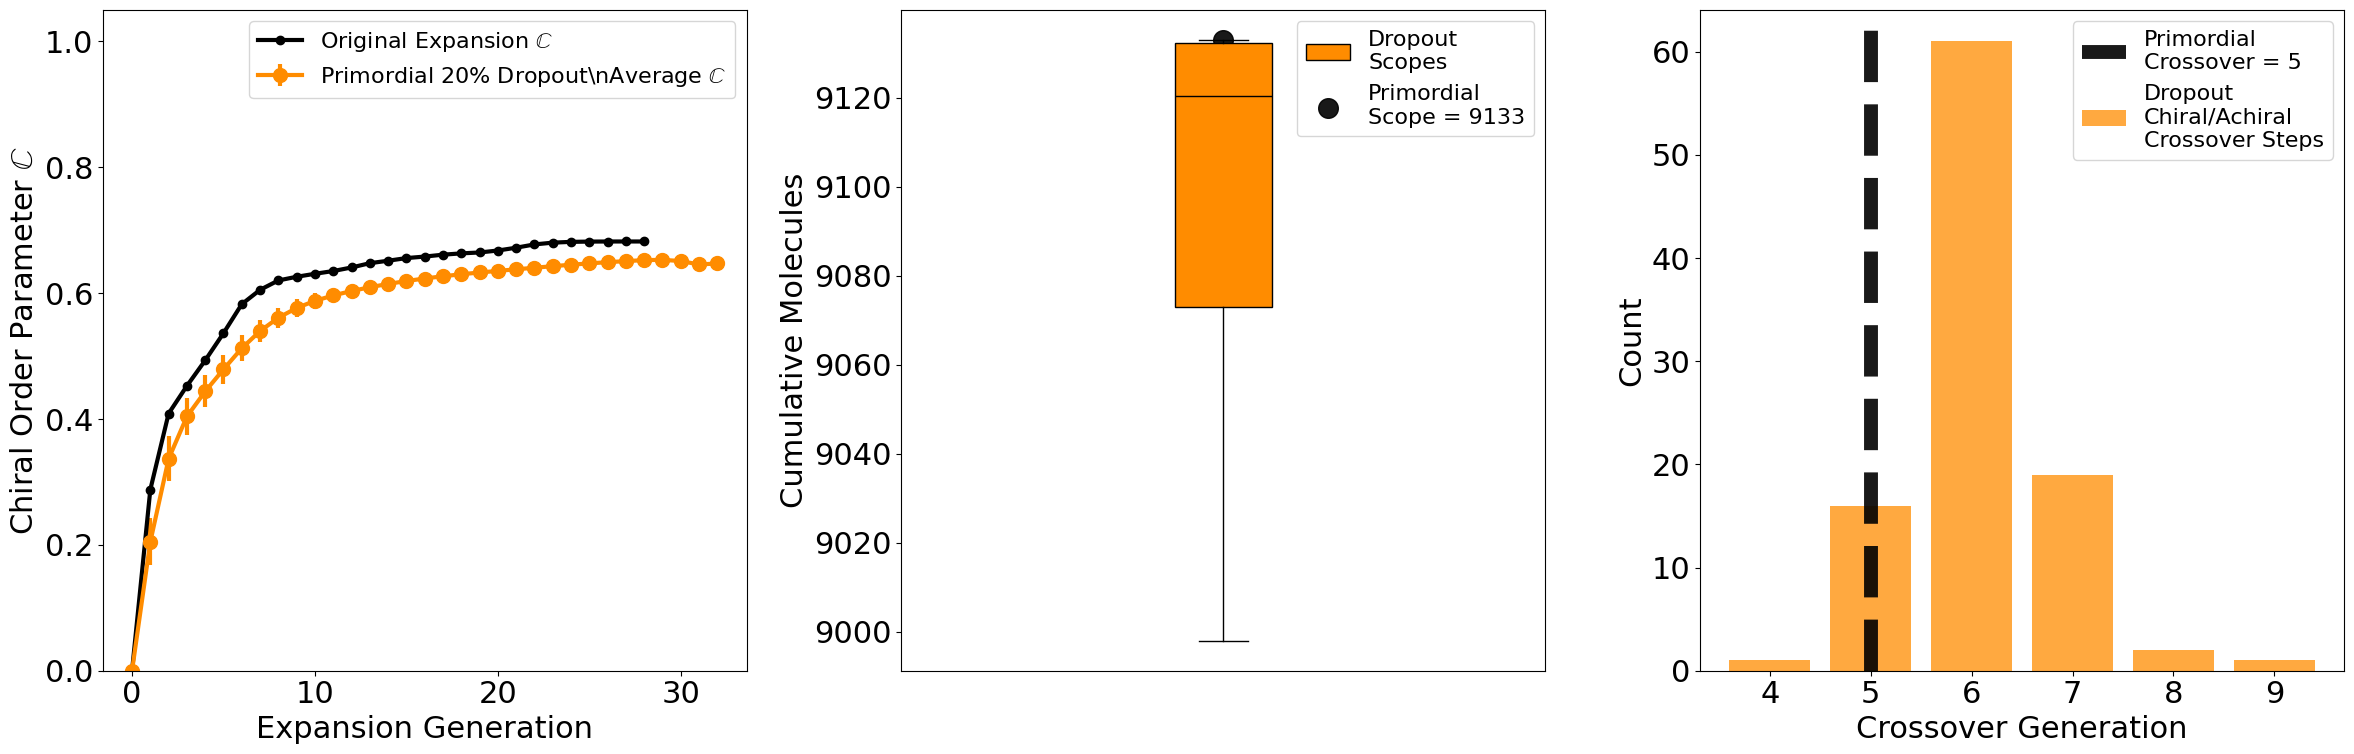

In [ ]:
# fig_count = 8

dropout_color = "darkorange"

plt.figure(figsize=(24, 8))
gs = gridspec.GridSpec(1, 3)

### Chiral order parameter by expansion step
ax1 = plt.subplot(gs[0, 0])
# Chiral errorbar
ax1.errorbar(x=np.arange(0, len(dropout_avg_percentages_chiral), 1),
             y=dropout_avg_percentages_chiral,
             yerr=dropout_std_percentages_chiral,
             color=dropout_color,
             marker="o",
             linewidth=3,
             markersize=10,
             label=r"Primordial 20% Dropout\nAverage $\mathbb{C}$")

ax1.plot(original_percent_chiral,
         "o-",
         color="k",
         linewidth=3,
         label=r"Original Expansion $\mathbb{C}$")

ax1.set_ylim([0, 1.05])
ax1.set_xlabel("Expansion Generation", fontsize=22)
ax1.set_ylabel(r"Chiral Order Parameter $\mathbb{C}$", fontsize=22)
ax1.tick_params(axis='both', which='both', labelsize=22)
ax1.legend(facecolor="white", prop={"size": 16})

### Boxplot
ax2 = plt.subplot(gs[0, 1])
bplot = ax2.boxplot(dropout_scopes, label="Dropout\nScopes", patch_artist=True, showfliers=False)
ax2.scatter(x=1, y=cum_chiral_count[-1] + cum_achiral_count[-1], s=200, color="k", alpha=0.9,
            label=f"Primordial\nScope = {cum_chiral_count[-1] + cum_achiral_count[-1]}")

for patch, color in zip(bplot['boxes'], [dropout_color]):
    patch.set_facecolor(color)

for median in bplot['medians']:
    median.set_color('k')

ax2.set_ylabel("Cumulative Molecules", fontsize=22)
ax2.tick_params(axis='both', which='both', labelsize=22)
ax2.set_xticklabels("")
ax2.set_xticks([])
ax2.legend(facecolor="white", prop={"size": 16})

### Dropout crossover stats
ax3 = plt.subplot(gs[0, 2])
labels, counts = np.unique(dropout_crossover_steps, return_counts=True)
ax3.bar(labels, counts, color=dropout_color, label="Dropout\nChiral/Achiral\nCrossover Steps", alpha=0.75)
ax3.axvline(x=achiral_chiral_crossover_step, color="k", lw=10, alpha=0.9, linestyle="--",
            label=f"Primordial\nCrossover = {achiral_chiral_crossover_step}")

ax3.set_xlabel("Crossover Generation", fontsize=22)
ax3.set_ylabel("Count", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 16})

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

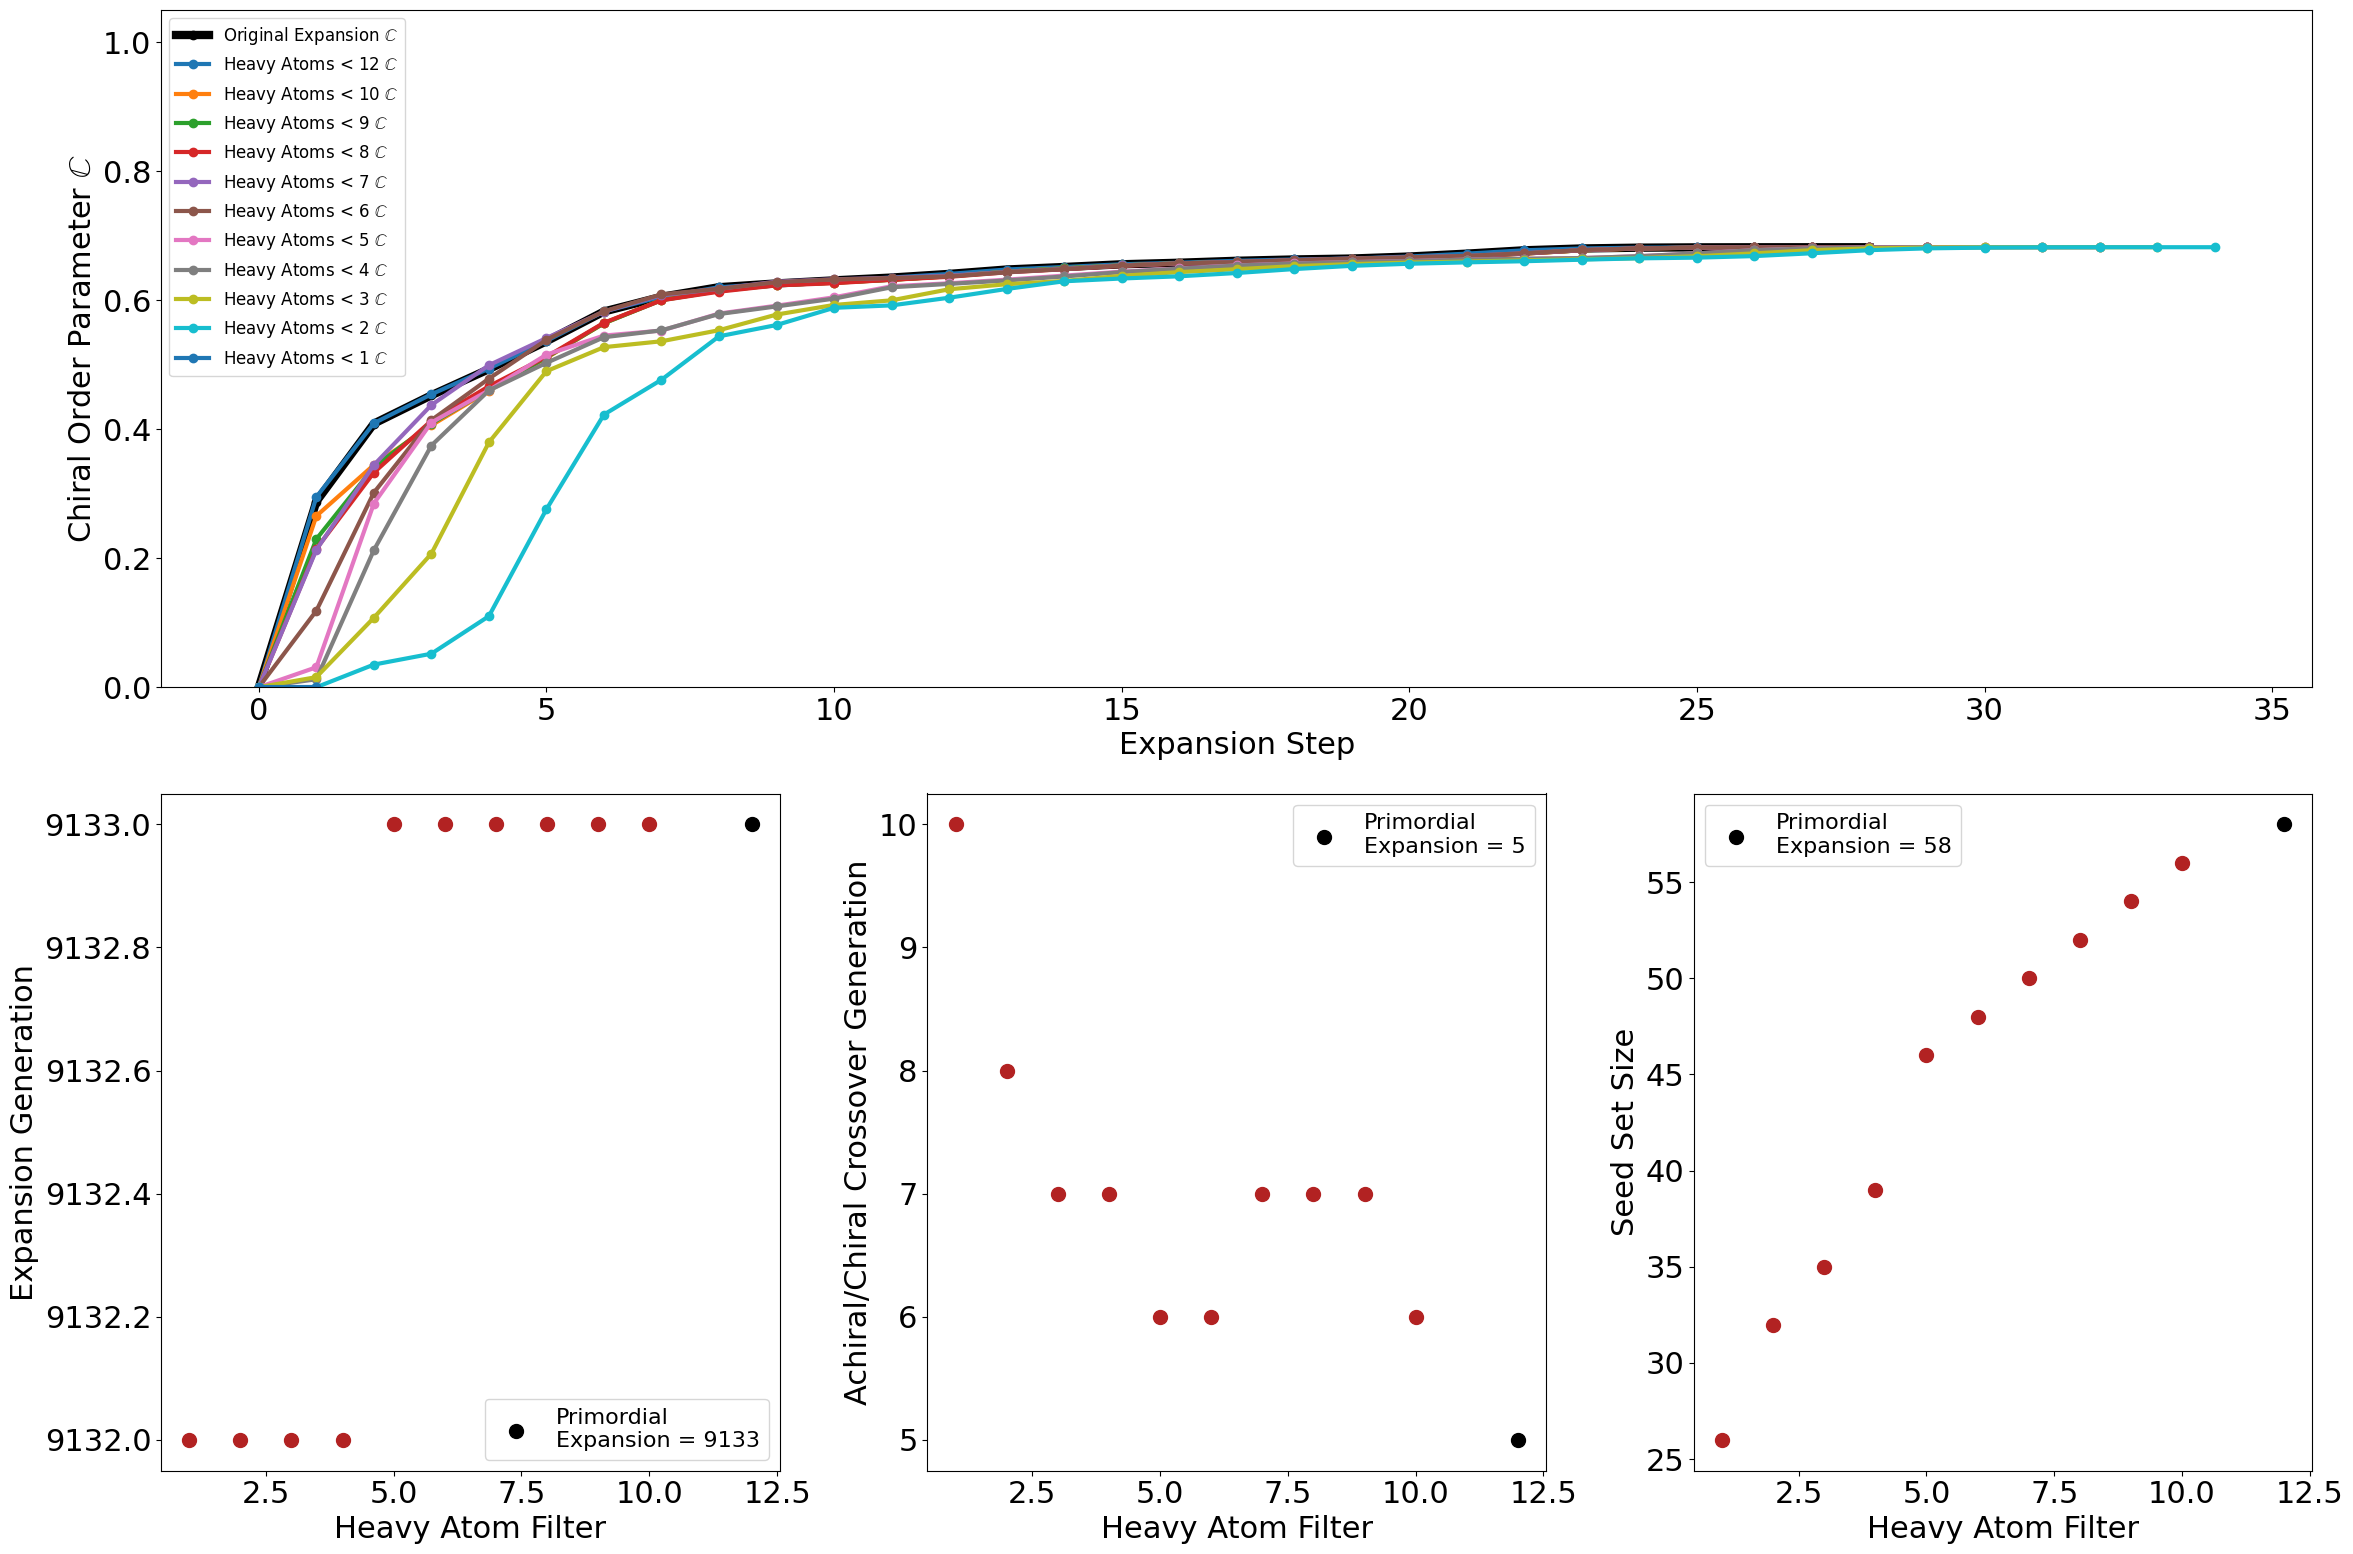

In [27]:
# fig_count = 9
sizefilter_color = "firebrick"

plt.figure(figsize=(24, 16))
gs = gridspec.GridSpec(2, 3)

### Heavy Atom filtered expansions
ax1 = plt.subplot(gs[0, :])
ax1.plot(original_percent_chiral,
         "o-",
         color="k",
         linewidth=6,
         label=r"Original Expansion $\mathbb{C}$")

for i in range(len(sizefilter_chiral_count)):
    filter_chiral_percentage = []
    for j in range(len(sizefilter_chiral_count[i])):
        filter_chiral_percentage.append(
            sizefilter_chiral_count[i][j] / (sizefilter_chiral_count[i][j] + sizefilter_achiral_count[i][j]))
    ax1.plot(filter_chiral_percentage,
             "o-",
             linewidth=3,
             label=f"Heavy Atoms < {unique_heavy_atoms[i]}" + r" $\mathbb{C}$")

ax1.set_ylim([0, 1.05])
ax1.set_xlabel("Expansion Step", fontsize=22)
ax1.set_ylabel(r"Chiral Order Parameter $\mathbb{C}$", fontsize=22)
ax1.tick_params(axis='both', which='both', labelsize=22)
ax1.legend(facecolor="white", prop={"size": 12})

### Expansion scopes
ax2 = plt.subplot(gs[1, 0])
ax2.scatter(x=unique_heavy_atoms[1:-1], y=sizefilter_scopes[:-1], color=sizefilter_color, s=100)
ax2.scatter(x=[12], y=[cum_chiral_count[-1] + cum_achiral_count[-1]], color="k",
            label=f"Primordial\nExpansion = {cum_chiral_count[-1] + cum_achiral_count[-1]}", s=100)

ax2.set_ylabel("Expansion Generation", fontsize=22)
ax2.set_xlabel("Heavy Atom Filter", fontsize=22)
ax2.tick_params(axis='both', which='both', labelsize=22)
ax2.legend(facecolor="white", prop={"size": 16})

### Expansion crossovers
ax3 = plt.subplot(gs[1, 1])
ax3.scatter(x=unique_heavy_atoms[1:-1], y=sizefilter_crossover_steps, color=sizefilter_color, s=100)
ax3.scatter(x=[12], y=[achiral_chiral_crossover_step], color="k",
            label=f"Primordial\nExpansion = {achiral_chiral_crossover_step}", s=100)

ax3.set_ylabel("Achiral/Chiral Crossover Generation", fontsize=22)
ax3.set_xlabel("Heavy Atom Filter", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 16})

### Seed Set size per filter
ax3 = plt.subplot(gs[1, 2])
ax3.scatter(x=unique_heavy_atoms[1:-1], y=unique_heavy_atoms_seedSetSize[:-1], color=sizefilter_color, s=100)
ax3.scatter(x=[12], y=[cum_chiral_count[0] + cum_achiral_count[0]], color="k",
            label=f"Primordial\nExpansion = {cum_chiral_count[0] + cum_achiral_count[0]}", s=100)

ax3.set_ylabel("Seed Set Size", fontsize=22)
ax3.set_xlabel("Heavy Atom Filter", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 16})

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

## LUCA Expansions

In [28]:
### Adding LUCA cpds to Sample Seeds
with open("../Data/LUCA_ec_compound_unique_list_clean.json", "r") as f:
    luca_cpds = json.load(f)

temp_cpds = list(luca_cpds["Luca"])
print(f"Number of LUCA compounds in seed set: {len(temp_cpds)}")
### Connected dataframe with full_figures scripts
curated_SS_df = pd.read_csv("../Data/curated_SeedSets.csv")
if "LUCA" not in list(curated_SS_df.columns):
    curated_SS_df["LUCA"] = pd.Series(temp_cpds)
    curated_SS_df.to_csv("../Data/curated_SeedSets.csv")

seed_df = pd.read_csv("../Data/SampleSeeds.csv")
for i, row in seed_df.iterrows():
    if row["Compound_id"] in (luca_cpds["Luca"]) and "LUCA" not in row["Source"]:
        source_str = row["Source"] + " LUCA"
        seed_df.at[i, 'Source'] = source_str
        temp_cpds.remove(row["Compound_id"])

for new_cpd in temp_cpds:
    if new_cpd not in list(seed_df["Compound_id"]):
        seed_df.loc[len(seed_df)] = [new_cpd, 'TODO', 'LUCA', False]

seed_df.to_csv("../Data/SampleSeeds.csv", index=False)

seed_df = pd.read_csv("../Data/SampleSeeds.csv", index_col=0)

Number of LUCA compounds in seed set: 438


In [29]:
#Run network expansion processing
# Seed set
seed_name = "LUCA"
rxn_db = reaction_file
max_generation = 1000  #Arbitrarily large 

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))

compound_scope = set.union(*reaction_scope.stack())
seed_candidates = pd.read_csv(f'{data_folder}/SampleSeeds.csv', index_col=0)
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seed_sets = {
    i: seed_scope.query('Source.str.contains("' + i + '")').index
    for i in seed_groups
}
print(f"- Seed Set ({seed_name}) -")

### Run network expansion on original seed set
results = dict()
for name, seeds in seed_sets.items():
    print(seeds)
    results[name] = expand_from_seed_set(seeds=seeds,
                                         reactions=reaction_scope,
                                         max_gen=max_generation)
    results[name]['bipartite_edgelist'] = make_bipartite_edge_list(results[name]['edge_pool'])


### Process expansion (including chiral %s at each step & heavy atom count)

summaries = {
    'compound count':
        result_to_df(results, key='cps', to_apply=lambda x: x.sum()),
    'reaction count':
        result_to_df(results, key='rns', to_apply=lambda x: x.sum()),
    'chiral compound count':
        get_compound_chiral_count(results[seed_name]["cps"], keggC_df, chiral_flag=True),
    'achiral compound count':
        get_compound_chiral_count(results[seed_name]["cps"], keggC_df, chiral_flag=False),
    'chiral fraction':
        result_to_df(results, key='chiral_fraction', to_apply=lambda x: x),
    'chiral avg heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=True,
                                          calc="mean"),
    'achiral avg heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=False,
                                          calc="mean"),
    'chiral std heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=True,
                                          calc="std"),
    'achiral std heavy atoms':
        get_heavy_atoms_per_gen_from_kegg(results[seed_name]["cps"],
                                          keggC_df,
                                          chiral_flag=False,
                                          calc="std")
}

cum_chiral_count = summaries["chiral compound count"][0].to_list()
cum_achiral_count = summaries["achiral compound count"][0].to_list()

- Seed Set (LUCA) -
Index(['C00033', 'C00283', 'C00288', 'C00001', 'C00009', 'C00011', 'C00014',
       'C00080', 'C00022', 'C00026',
       ...
       'C20864', 'C20904', 'C20905', 'C20969', 'C21004', 'C21031', 'C21748',
       'C21749', 'C21750', 'C21751'],
      dtype='object', name='Compound_id', length=408)


In [30]:
new_chiral_count = []
new_achiral_count = []
for i in range(len(cum_chiral_count)):
    if i > 0:
        new_chiral_count.append(cum_chiral_count[i] - cum_chiral_count[i - 1])
        new_achiral_count.append(cum_achiral_count[i] - cum_achiral_count[i - 1])
    else:
        new_chiral_count.append(0)
        new_achiral_count.append(0)

new_total_count = [x + y for x, y in zip(new_chiral_count, new_achiral_count)]


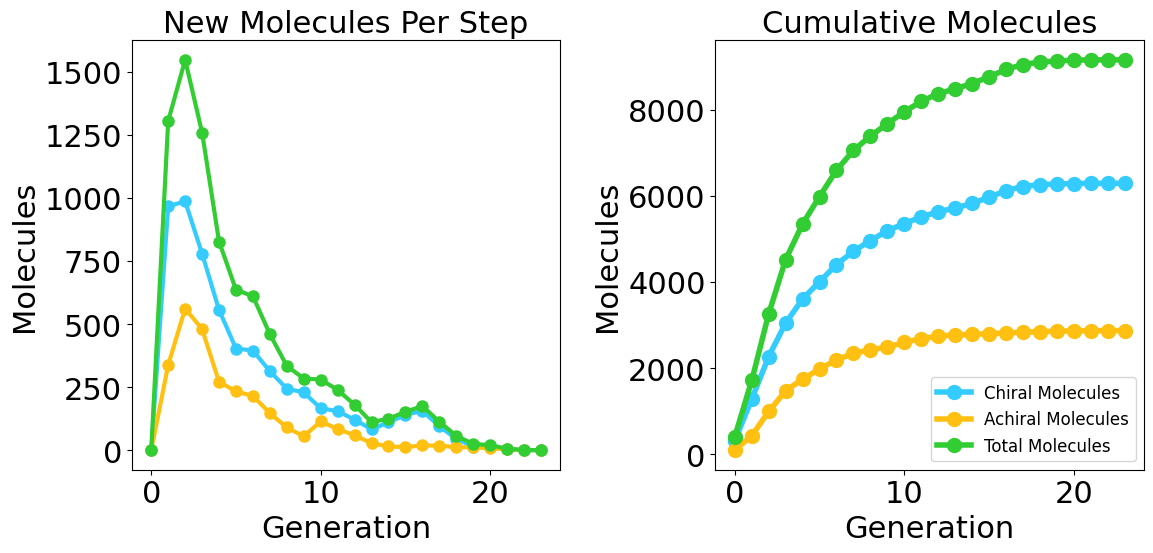

In [31]:
# fig_count = 10

### LUCA Expansion plots
plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(1, 2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0, 0])

ax1.plot(new_chiral_count, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Molecules", )
ax1.plot(new_achiral_count, color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Molecules")
ax1.plot(np.arange(0, len(new_chiral_count), 1), new_total_count,
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Molecules")

ax1.set_xlabel("Generation", fontsize=22)
ax1.set_ylabel("Molecules", fontsize=22)
ax1.tick_params(axis='both', which='major', labelsize=22)
ax1.set_title("New Molecules Per Step", fontsize=22)

ax2 = plt.subplot(gs[0, 1])
ax2.plot(cum_chiral_count, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Molecules", )
ax2.plot(cum_achiral_count, color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Molecules")
ax2.plot(np.arange(0, len(cum_chiral_count), 1), summaries["compound count"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Molecules")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Generation", fontsize=22)
ax2.set_ylabel("Molecules", fontsize=22)
ax2.tick_params(axis='both', which='major', labelsize=22)
ax2.set_title("Cumulative Molecules", fontsize=22)

plt.tight_layout()
plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

# Universality


In [32]:
# Reset Matplotlib defaults
import matplotlib.pyplot as plt

font = {"sans-serif": "DejaVu Sans", "size": 22}
for key, value in font.items():
    plt.rcParams.update({"font." + key: value})

plt.rcParams.update({"font.size": 22})
# And add universality colors
mg_color = "#009E73"
e_color = "#E69F03"
b_color = "#0B77B5"
a_color = "#D65E00"
pt_color = "#EA9999"
chiral_ls = "solid"
achiral_ls = "dashed"

In [33]:
def make_AUC(u, label, c, ax):
    yvals = list(u.values())
    xvals = np.linspace(0, 1, num=len(yvals))
    #Calculate AUC using composite travezoidal rule
    area = np.trapz(yvals, dx=xvals[1])

    if c == "":
        ax.plot(xvals, yvals, label=label + " AUC=" + str(round(area, 2)))
    else:
        ax.plot(xvals, yvals, label=label + " AUC=" + str(round(area, 2)), color=c)

    ax.legend()


def make_AUC_dashes(u, label, c, ls, ax):
    yvals = list(u.values())
    xvals = np.linspace(0, 1, num=len(yvals))

    #Calculate AUC using composite travezoidal rule
    area = np.trapz(yvals, dx=xvals[1])

    ax.plot(xvals, yvals, label=label + " AUC=" + str(round(area, 2)), color=c,
            linestyle=ls, linewidth=4)

    ax.legend(facecolor="white", prop={"size": 13.5})

    return yvals


#Separate domains into chiral vs achiral
#df is the chiral dataframe (columns=['Index', 'C', 'Smiles', 'n_chiral_centers'])
def find_chiral(u, df):
    achiral = {}
    chiral = {}

    for index, row in df.iterrows():
        if row["compound_id"] in u:
            if row["n_chiral_centers"] > 0:
                chiral[row["compound_id"]] = u[row["compound_id"]]
            else:
                achiral[row["compound_id"]] = u[row["compound_id"]]

    return chiral, achiral


def get_chiral_difference(chiral_values, achiral_values, c, l, ax):
    #Step 1: get rank-order percentile values
    m_chiral_percentiles = []
    for i in np.linspace(0, len(chiral_values) - 1, 100):
        m_chiral_percentiles.append(chiral_values[int(i)])

    m_achiral_percentiles = []
    for i in np.linspace(0, len(achiral_values) - 1, 100):
        m_achiral_percentiles.append(achiral_values[int(i)])

    #Step 2: find difference
    m_diffs = list(np.array(m_chiral_percentiles) - np.array(m_achiral_percentiles))

    #Step 3: plot
    label = ax.plot(m_diffs, color=c, linewidth=3, label=l)

    return label

In [34]:
#Read in occurence data & create universality percentages

occurrence_df = pd.read_csv('../Data/omics/compound2occurrence.csv', header=0, index_col=0)
order = ['Bacteria', 'Archaea', 'Eukaryota', 'Metagenome']
num_samples = occurrence_df.loc['N', order].copy()
num_bacteria, num_archaea, num_eukarya, num_metagenomes = num_samples.to_list()
occurrence_df = occurrence_df[order].drop(index=['N']).mask(lambda x: x==0)
# Translate occurances into % universality
universality_df = (occurrence_df / num_samples)

print(f"- Total JGI Sample Count: {num_bacteria + num_archaea + num_eukarya + num_metagenomes} -")
    
a_cpd_occurances = occurrence_df['Archaea'].dropna().to_dict()
b_cpd_occurances = occurrence_df['Bacteria'].dropna().to_dict()
e_cpd_occurances = occurrence_df['Eukaryota'].dropna().to_dict()
m_cpd_occurances = occurrence_df['Metagenome'].dropna().to_dict()
    
a_cpd_universality = universality_df['Archaea'].dropna().to_dict()
b_cpd_universality = universality_df['Bacteria'].dropna().to_dict()
e_cpd_universality = universality_df['Eukaryota'].dropna().to_dict()
m_cpd_universality = universality_df['Metagenome'].dropna().to_dict()

#Create universality dictionaries across bacteria, archaea, and eukarya (and various combinations) - easier for plotting & calculations

#Convert keys to integers, combine dictionaries
a_cpd_occurances = dict([a, int(x)] for a, x in a_cpd_occurances.items())
b_cpd_occurances = dict([a, int(x)] for a, x in b_cpd_occurances.items())
e_cpd_occurances = dict([a, int(x)] for a, x in e_cpd_occurances.items())
ba_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances)
pt_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances) + Counter(e_cpd_occurances)

#Find universality of bacteria & archaea combined
ba_cpd_universality = {}
num_ba = num_archaea + num_bacteria
for item in ba_occurances.items():
    ba_cpd_universality[item[0]] = float(item[1]) / num_ba

#Universality of pan-taxa (bacteria, archaea, eukarya combined)
pt_cpd_universality = {}
num_pt = num_archaea + num_bacteria + num_eukarya
for item in pt_occurances.items():
    pt_cpd_universality[item[0]] = float(item[1]) / num_pt

#Find unversalities, and rank-order each
a_chiral_universality, a_achiral_universality = find_chiral(a_cpd_universality, keggC_df)
a_chiral_universality = {k: v for k, v in sorted(a_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
a_achiral_universality = {k: v for k, v in
                          sorted(a_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

b_chiral_universality, b_achiral_universality = find_chiral(b_cpd_universality, keggC_df)
b_chiral_universality = {k: v for k, v in sorted(b_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
b_achiral_universality = {k: v for k, v in
                          sorted(b_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

e_chiral_universality, e_achiral_universality = find_chiral(e_cpd_universality, keggC_df)
e_chiral_universality = {k: v for k, v in sorted(e_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
e_achiral_universality = {k: v for k, v in
                          sorted(e_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

m_chiral_universality, m_achiral_universality = find_chiral(m_cpd_universality, keggC_df)
m_chiral_universality = {k: v for k, v in sorted(m_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
m_achiral_universality = {k: v for k, v in
                          sorted(m_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

ba_chiral_universality, ba_achiral_universality = find_chiral(ba_cpd_universality, keggC_df)
ba_chiral_universality = {k: v for k, v in
                          sorted(ba_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
ba_achiral_universality = {k: v for k, v in
                           sorted(ba_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

pt_chiral_universality, pt_achiral_universality = find_chiral(pt_cpd_universality, keggC_df)
pt_chiral_universality = {k: v for k, v in
                          sorted(pt_chiral_universality.items(), key=lambda item: item[1], reverse=True)}
pt_achiral_universality = {k: v for k, v in
                           sorted(pt_achiral_universality.items(), key=lambda item: item[1], reverse=True)}

- Total JGI Sample Count: 40023 -


/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4226991366.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(yvals, dx=xvals[1])


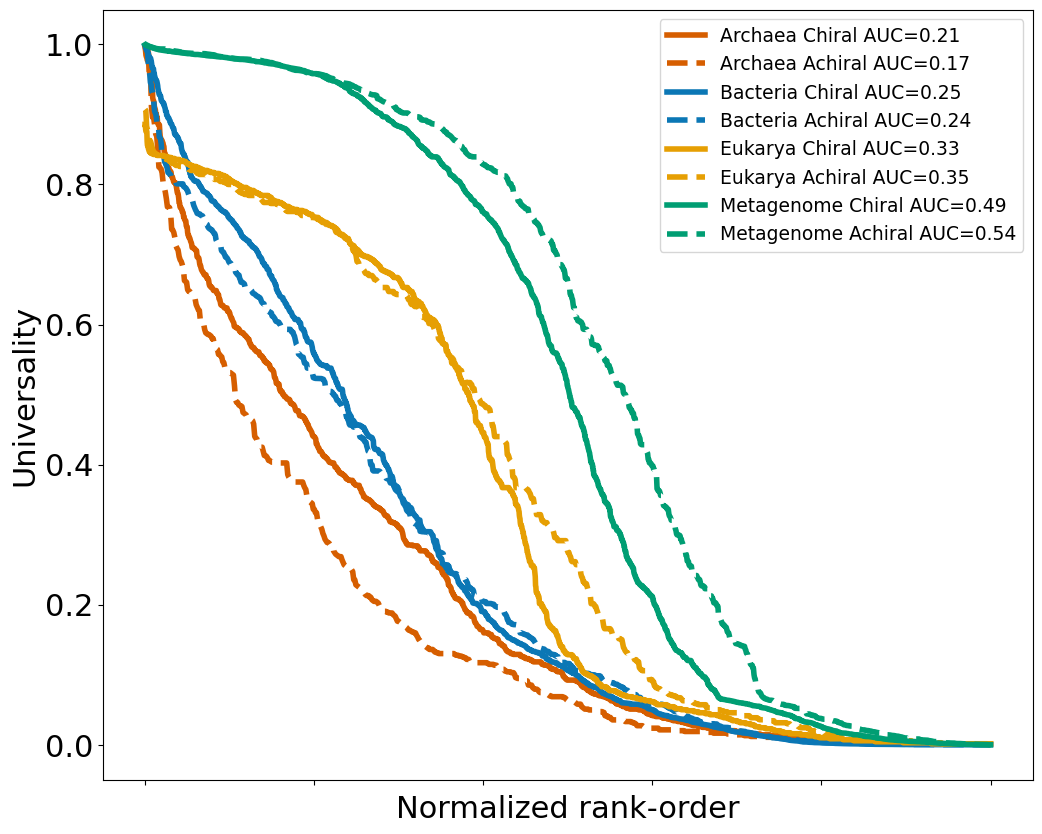

In [35]:
# fig_count = 11

#All three domains together
fig, ax = plt.subplots(figsize=(12, 10))
a_chiral = make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax)
a_achiral = make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax)

b_chiral = make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax)
b_achiral = make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax)

e_chiral = make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax)
e_achiral = make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax)

m_chiral = make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax)
m_achiral = make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax)

ax.set_ylabel("Universality", size=22)
ax.set_xlabel("Normalized rank-order", size=22)
ax.set_xticklabels("")
ax.tick_params(axis='both', which='major', labelsize=22)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1


/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4226991366.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(yvals, dx=xvals[1])
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4226991366.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(yvals, dx=xvals[1])
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4226991366.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(yvals, dx=xvals[1])
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4226991366.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = n

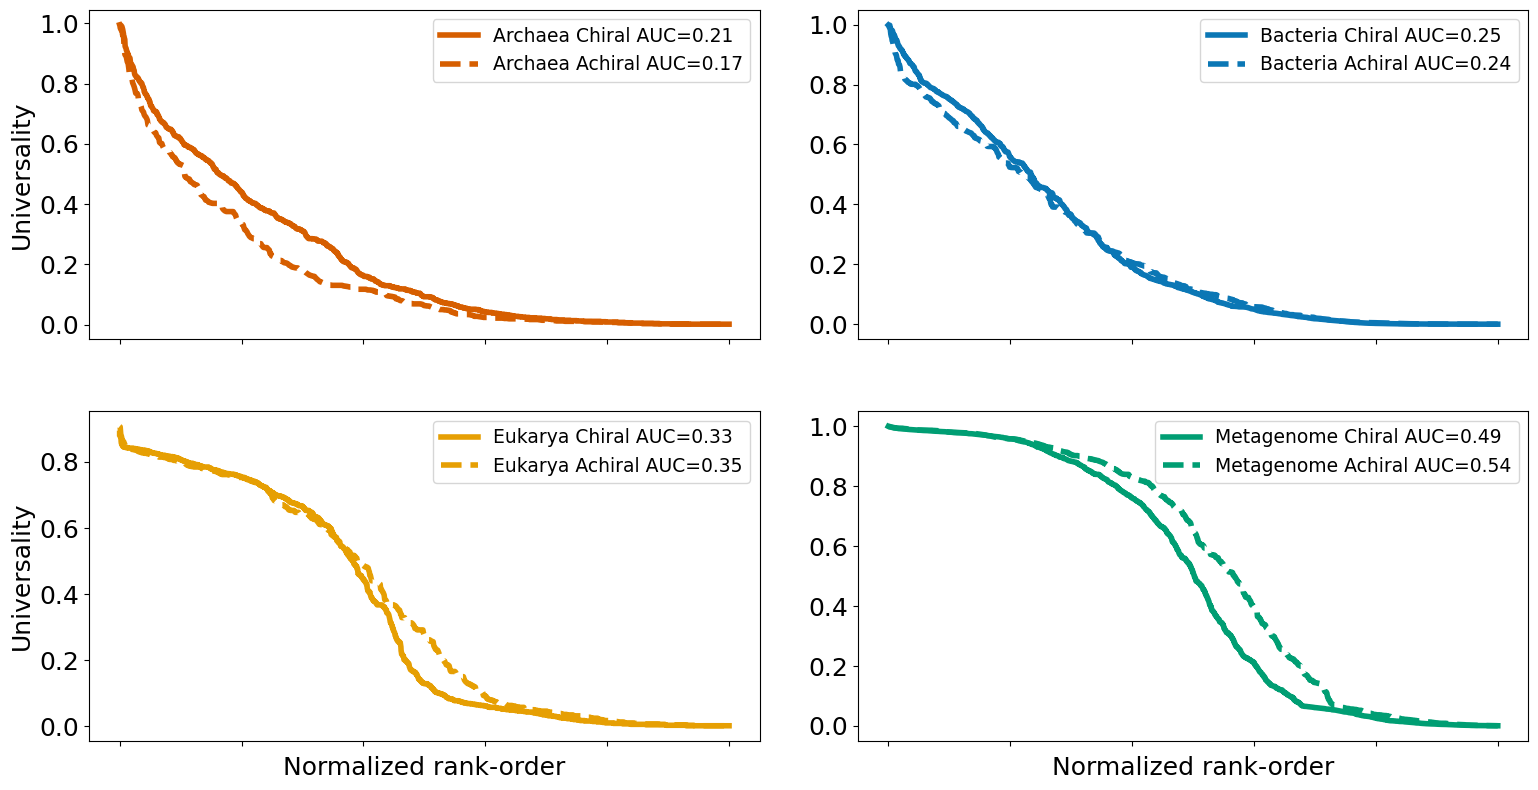

In [36]:
# fig_count = 12

plt.figure(figsize=(16, 16))
gs = gridspec.GridSpec(4, 2)

ax1 = plt.subplot(gs[0, 0])
make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax1)
make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax1)
ax1.set_xticklabels("")
ax1.tick_params(axis='both', which='major', labelsize=18)

ax2 = plt.subplot(gs[0, 1])
make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax2)
make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax2)
ax2.set_xticklabels("")
ax2.tick_params(axis='both', which='major', labelsize=18)

ax3 = plt.subplot(gs[1, 0])
make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax3)
make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax3)
ax3.set_xticklabels("")
ax3.tick_params(axis='both', which='major', labelsize=18)

ax4 = plt.subplot(gs[1, 1])
make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax4)
make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax4)
ax4.set_xticklabels("")
ax4.tick_params(axis='both', which='major', labelsize=18)

ax1.set_ylabel("Universality", size=18)
ax3.set_ylabel("Universality", size=18)
ax3.set_xlabel("Normalized rank-order", size=18)
ax4.set_xlabel("Normalized rank-order", size=18)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1


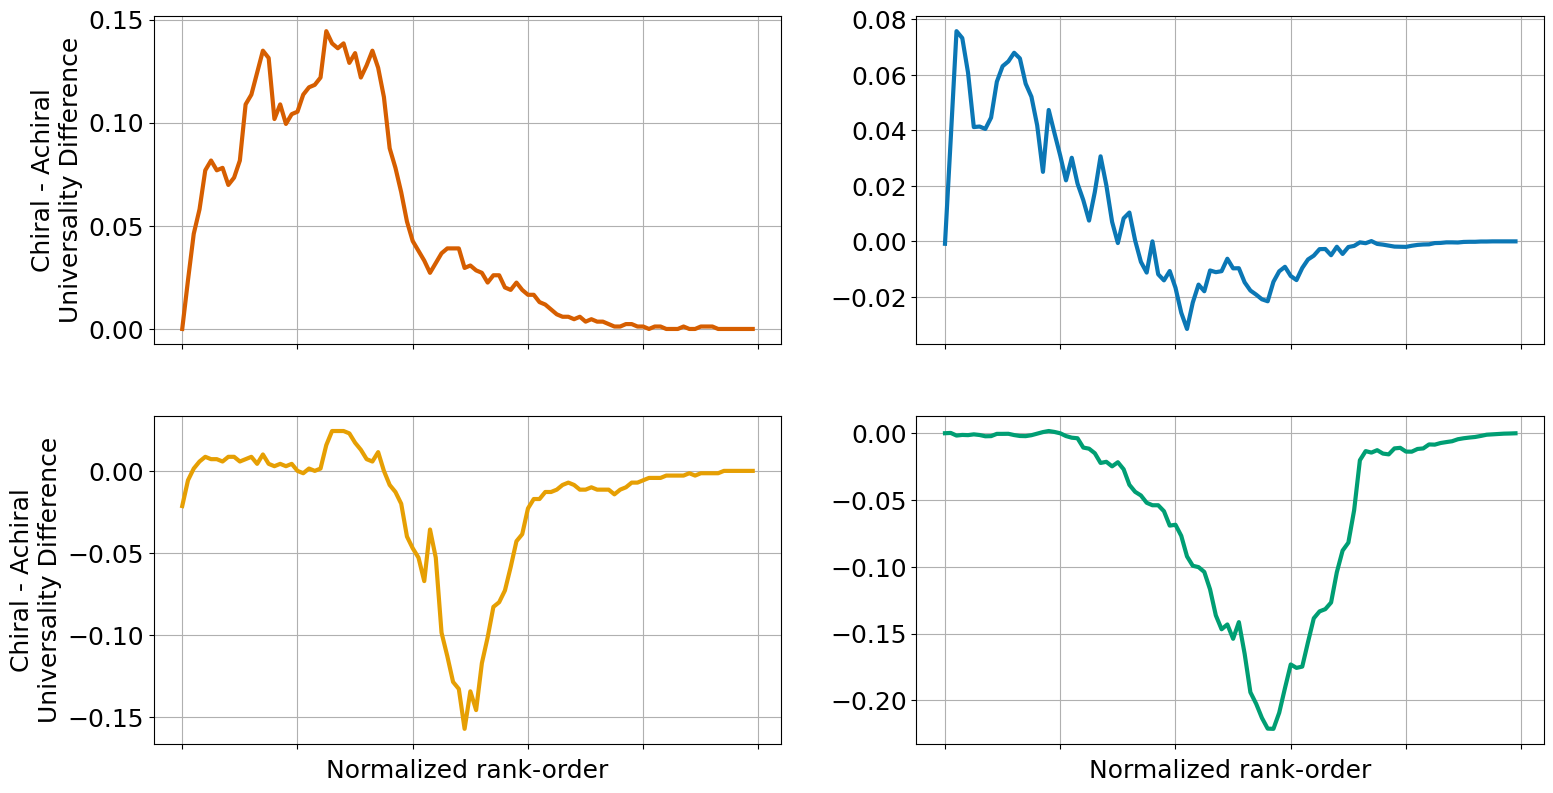

In [37]:
# fig_count = 13

plt.figure(figsize=(16, 16))
gs = gridspec.GridSpec(4, 2)

ax1 = plt.subplot(gs[0, 0])
get_chiral_difference(a_chiral, a_achiral, a_color, "Archaea", ax1)
ax1.set_xticklabels("")
ax1.tick_params(axis='both', which='major', labelsize=18)

ax2 = plt.subplot(gs[0, 1])
get_chiral_difference(b_chiral, b_achiral, b_color, "Bacteria", ax2)
ax2.set_xticklabels("")
ax2.tick_params(axis='both', which='major', labelsize=18)

ax3 = plt.subplot(gs[1, 0])
get_chiral_difference(e_chiral, e_achiral, e_color, "Eukarya", ax3)
ax3.set_xticklabels("")
ax3.tick_params(axis='both', which='major', labelsize=18)

ax4 = plt.subplot(gs[1, 1])
get_chiral_difference(m_chiral, m_achiral, mg_color, "Metagenome", ax4)
ax4.set_xticklabels("")
ax4.tick_params(axis='both', which='major', labelsize=18)

ax1.set_ylabel("Chiral - Achiral\nUniversality Difference", size=18)
ax3.set_ylabel("Chiral - Achiral\nUniversality Difference", size=18)
ax3.set_xlabel("Normalized rank-order", size=18)
ax4.set_xlabel("Normalized rank-order", size=18)

ax1.grid()
ax2.grid()
ax3.grid()
ax4.grid()

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1


#### AUC scores for chiral modulating / conserving / achiral conserving domain-specific reactions

In [38]:
def get_AUC(yvals):
    xvals = np.linspace(0, 1, num=len(yvals))
    #Calculate AUC using composite travezoidal rule
    area = np.trapz(yvals, dx=xvals[1])
    return round(area, 3)


def plot_classes(universality, ax, c, title):
    modulating_universality = [u for r, u in universality.items() if r in modulating_rxns]
    chiral_conserve_universality = [u for r, u in universality.items() if r in chiral_conserving_rxns]
    achiral_conserve_universality = [u for r, u in universality.items() if r in achiral_conserving_rxns]

    ax.plot(modulating_universality, linestyle="solid", linewidth=3, color=c,
            label=f"Chiral Modulating\nAUC={get_AUC(modulating_universality)}")
    ax.plot(chiral_conserve_universality, linestyle="dashed", linewidth=3, color=c,
            label=f"Chiral Conserving\nAUC={get_AUC(chiral_conserve_universality)}")
    ax.plot(achiral_conserve_universality, linestyle="dotted", linewidth=3, color=c,
            label=f"Achiral Conserving\nAUC={get_AUC(achiral_conserve_universality)}")

    ax.legend(facecolor="white", prop={"size": 14})
    ax.set_title(title, color=c, size=20)


### Modulating - from Kamesh
modulate_df = pd.read_csv("../Data/kegg_reactions_with_mol_weights_comprehensive_v8.csv")

modulating = []
achiral_conserve = []
chiral_conserve = []

modulating_rxns = []
achiral_conserving_rxns = []
chiral_conserving_rxns = []

for i in range(0, max(modulate_df["Network_step"])):
    sub_df = modulate_df[modulate_df["Network_step"] == i]

    chiral_modulating_df = sub_df[sub_df["Chiral_modulating"] == 1]
    modulating.append(len(chiral_modulating_df))
    if not chiral_modulating_df.empty:
        modulating_rxns.extend(list(chiral_modulating_df["_key"]))

    achiral_conserving_df = sub_df[sub_df["Achiral_conserving"] == 1]
    achiral_conserve.append(len(achiral_conserving_df))
    if not achiral_conserving_df.empty:
        achiral_conserving_rxns.extend(list(achiral_conserving_df["_key"]))

    chiral_conserving_df = sub_df[sub_df["Chiral_conserving"] == 1]
    chiral_conserve.append(len(chiral_conserving_df))
    if not chiral_conserving_df.empty:
        chiral_conserving_rxns.extend(list(chiral_conserving_df["_key"]))

### Read in occurrence data & create universality percentages

rxn_occurrence_df = pd.read_csv('../Data/omics/reaction2occurrence.csv', header=0, index_col=0)
order = ['Bacteria', 'Archaea', 'Eukaryota', 'Metagenome']
num_samples = rxn_occurrence_df.loc['N', order].copy()
num_bacteria, num_archaea, num_eukarya, num_metagenomes = num_samples.to_list()
rxn_occurrence_df = rxn_occurrence_df[order].drop(index=['N']).mask(lambda x: x==0)
# Translate occurrences into % universality
rxn_universality_df = (rxn_occurrence_df / num_samples)

print(f"- Total JGI Sample Count: {num_bacteria + num_archaea + num_eukarya + num_metagenomes} -")
    
a_rxn_occurances = rxn_occurrence_df['Archaea'].dropna().to_dict()
b_rxn_occurances = rxn_occurrence_df['Bacteria'].dropna().to_dict()
e_rxn_occurances = rxn_occurrence_df['Eukaryota'].dropna().to_dict()
m_rxn_occurances = rxn_occurrence_df['Metagenome'].dropna().to_dict()
    
a_rxn_universality = rxn_universality_df['Archaea'].dropna().sort_values(ascending=False).to_dict()
b_rxn_universality = rxn_universality_df['Bacteria'].dropna().sort_values(ascending=False).to_dict()
e_rxn_universality = rxn_universality_df['Eukaryota'].dropna().sort_values(ascending=False).to_dict()
m_rxn_universality = rxn_universality_df['Metagenome'].dropna().sort_values(ascending=False).to_dict()


- Total JGI Sample Count: 40023 -


/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/1514771031.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(yvals, dx=xvals[1])


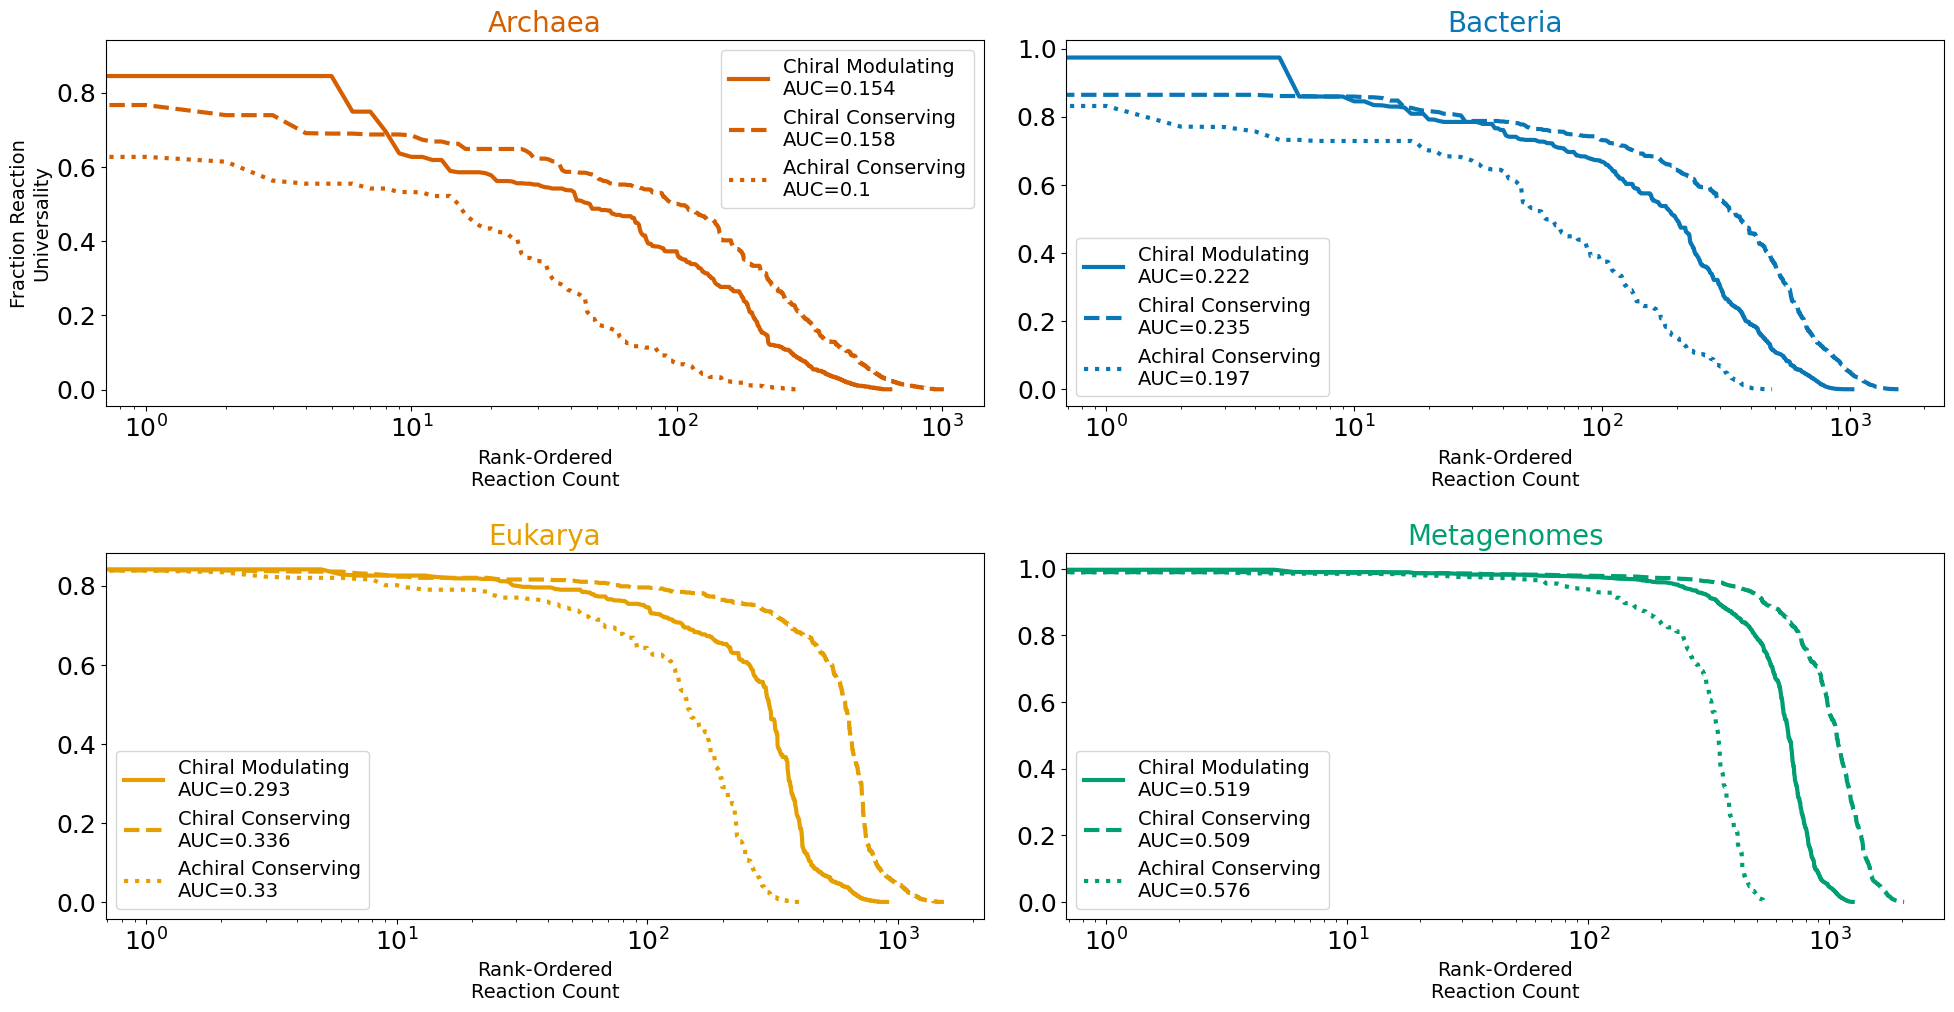

In [39]:
# fig_count = 14

### Goal - 4 plots (1 per domain) with AUC scores in legend
from matplotlib.gridspec import GridSpec

colors = {"archaea": "#D55E00",
          "bacteria": "#0977B5",
          "eukarya": "#E69F00",
          "metagenome": "#009E73",
          "pantaxa": "#EA9999",
          "chiral": "#34CCFF",
          "achiral": "#FFC012",
          "mixed": "#abdbfc",
          "luca": "grey"}

fig = plt.figure(figsize=(20,20))
gs = GridSpec(4, 2)

ax_archaea = fig.add_subplot(gs[0, 0])
ax_bacteria = fig.add_subplot(gs[0, 1])
ax_eukarya = fig.add_subplot(gs[1, 0])
ax_mg = fig.add_subplot(gs[1, 1])

plot_classes(a_rxn_universality, ax_archaea, colors["archaea"], "Archaea")
plot_classes(b_rxn_universality, ax_bacteria, colors["bacteria"], "Bacteria")
plot_classes(e_rxn_universality, ax_eukarya, colors["eukarya"], "Eukarya")
plot_classes(m_rxn_universality, ax_mg, colors["metagenome"], "Metagenomes")

ax_archaea.set_xscale("log")
ax_bacteria.set_xscale("log")
ax_eukarya.set_xscale("log")
ax_mg.set_xscale("log")

ax_archaea.tick_params(axis='both', which='major', labelsize=18)
ax_bacteria.tick_params(axis='both', which='major', labelsize=18)
ax_eukarya.tick_params(axis='both', which='major', labelsize=18)
ax_mg.tick_params(axis='both', which='major', labelsize=18)

ax_archaea.set_ylabel("Fraction Reaction\nUniversality", fontsize=14)
ax_archaea.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_bacteria.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_eukarya.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_mg.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

## JGI Scaling

<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\m'
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4018800743.py:23: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4018800743.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/4018800743.py:48: SyntaxWarning: invalid escape sequence '\m'
  ax3.set_ylabel("$\mathbb{C}$", fontsize=26)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/40188007

Slope: -0.000106 Intercept: 0.739776 R-squared: 0.346741 Std_err: 0.000004
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000027 Intercept: 0.653523 R-squared: 0.200469 Std_err: 0.000003
Slope: 0.000009 Intercept: 0.572096 R-squared: 0.097244 Std_err: 0.000000


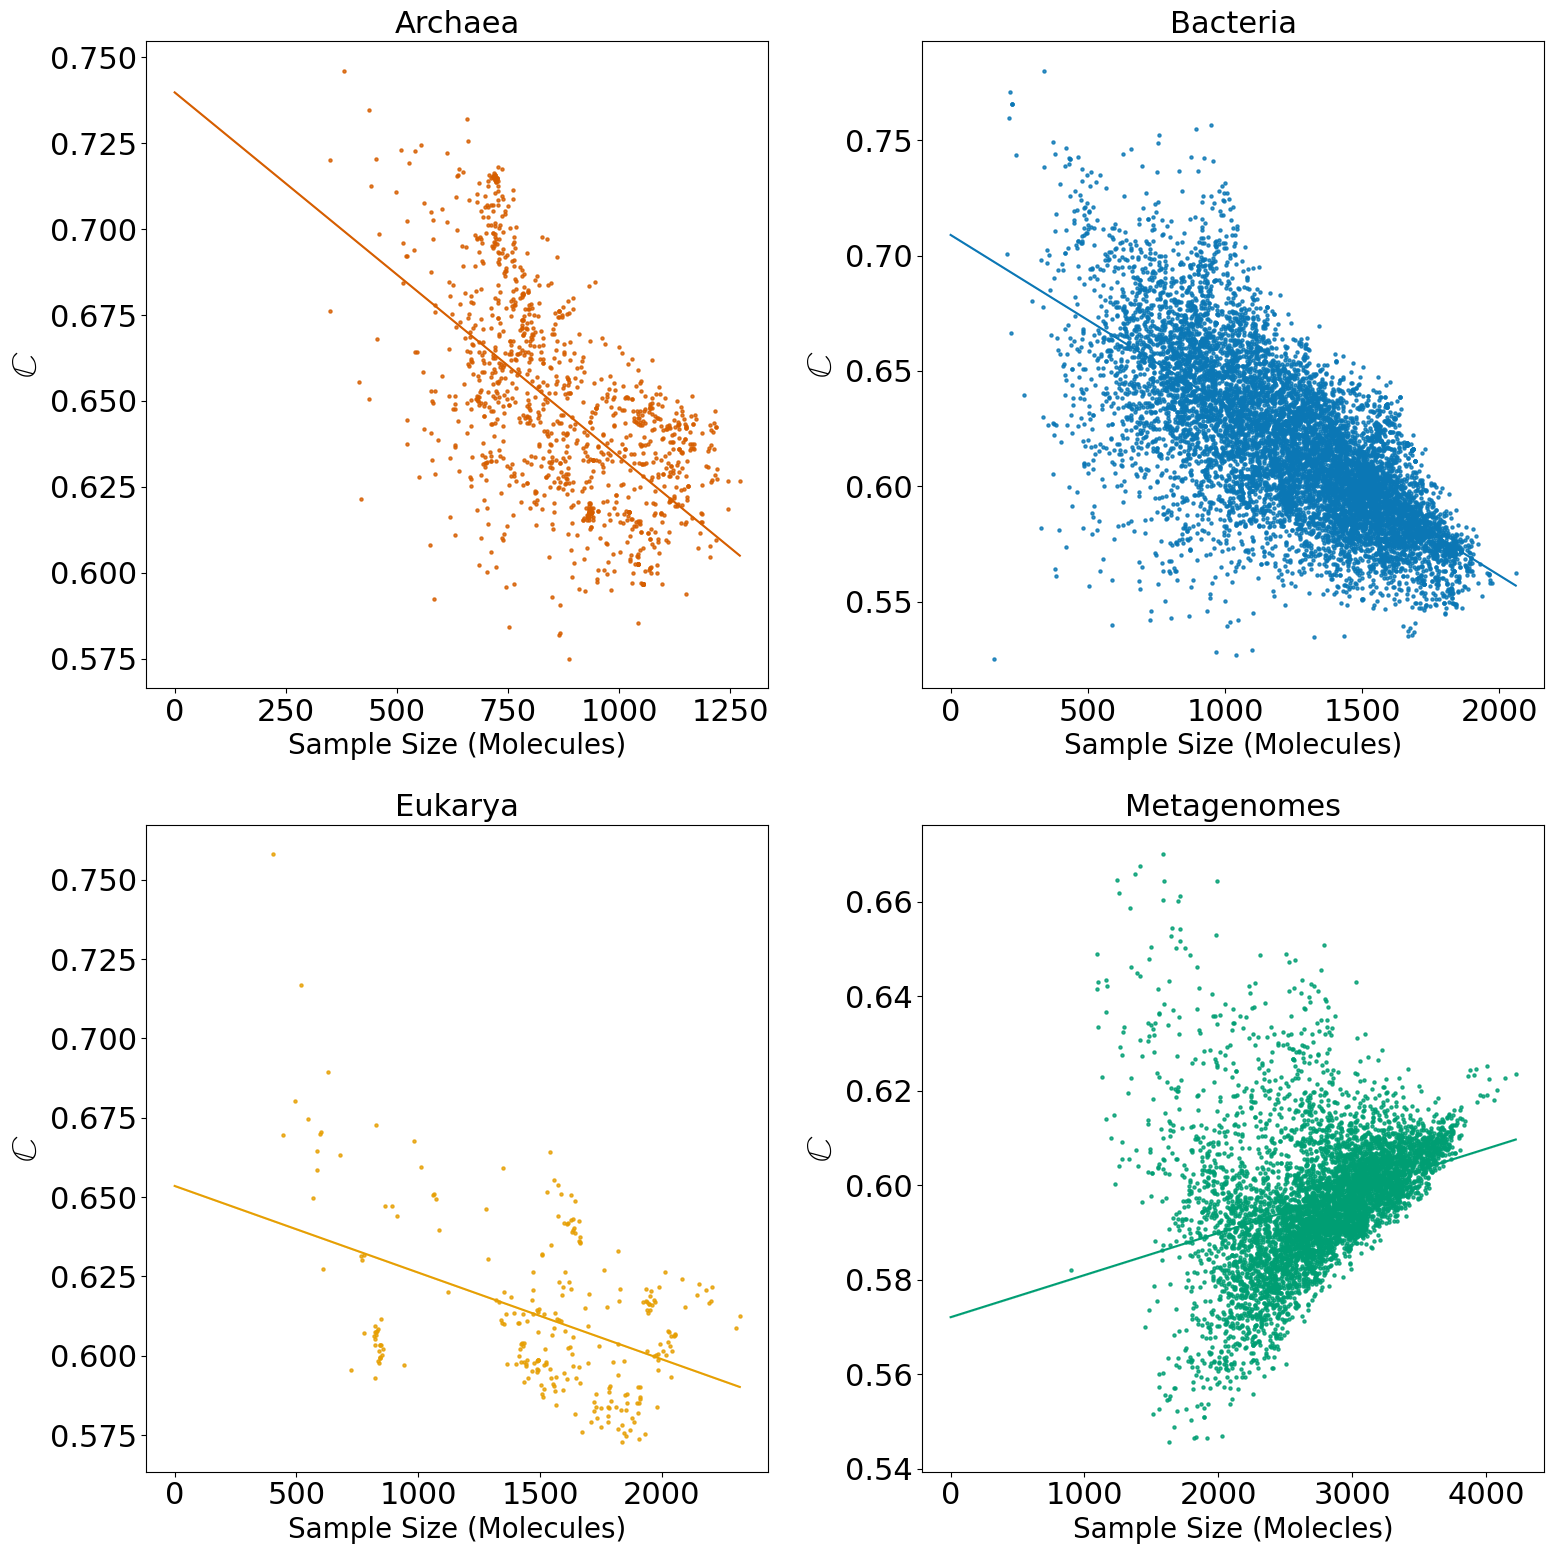

In [40]:
# fig_count = 15

data_dir = "../Data/"
df = dict()
for domain in ["Archaea", "Metagenome", "Bacteria", "Eukarya", "Biosphere", "LUCA"]:
    df[domain] = pd.read_csv(data_dir + "species_chirality_in_%s.csv" % domain)

color_number = {"LUCA": "#10D410", "Archaea": "#D65E00", "Bacteria": "#0B77B5",
                "Eukarya": "#E69F03", "Metagenome": "#009E73", "Biosphere": "#4B0092"}

plt.figure(figsize=(16, 16))
gs = gridspec.GridSpec(2, 2)

# Archaea
ax1 = plt.subplot(gs[0, 0])
handles = []
domain = "Archaea"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label=domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s)  #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Molecules)", fontsize=20)
ax1.set_title(domain, fontsize=22)

ax1 = plt.subplot(gs[0, 1])
handles = []
domain = "Bacteria"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label=domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s)  #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Molecules)", fontsize=20)
ax1.set_title(domain, fontsize=22)

#Eukarya
ax3 = plt.subplot(gs[1, 0])
handles = []
domain = "Eukarya"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax3.scatter(x, y, label=domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s)  #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax3)
ax3.set_ylabel("$\mathbb{C}$", fontsize=26)
ax3.set_xlabel("Sample Size (Molecules)", fontsize=20)
ax3.set_title(domain, fontsize=22)

#Metagenomes
ax4 = plt.subplot(gs[1, 1])
handles = []
domain = "Metagenome"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax4.scatter(x, y, label=domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s)  #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax4)
ax4.set_ylabel("$\mathbb{C}$", fontsize=26)
ax4.set_xlabel("Sample Size (Molecles)", fontsize=20)
ax4.set_title(domain + "s", fontsize=22)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/1243735569.py:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  ax = domain_achiral_fractions[toplot].plot(subplots=True, color=achiral_color, layout=(2, 2), legend=False, ax=ax,
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/1243735569.py:7: UserWarning: When passing multiple axes, layout keyword is ignored.
  ax = domain_chiral_fractions[toplot].plot(subplots=True, color=chiral_color, layout=(2, 2), legend=False, ax=ax,


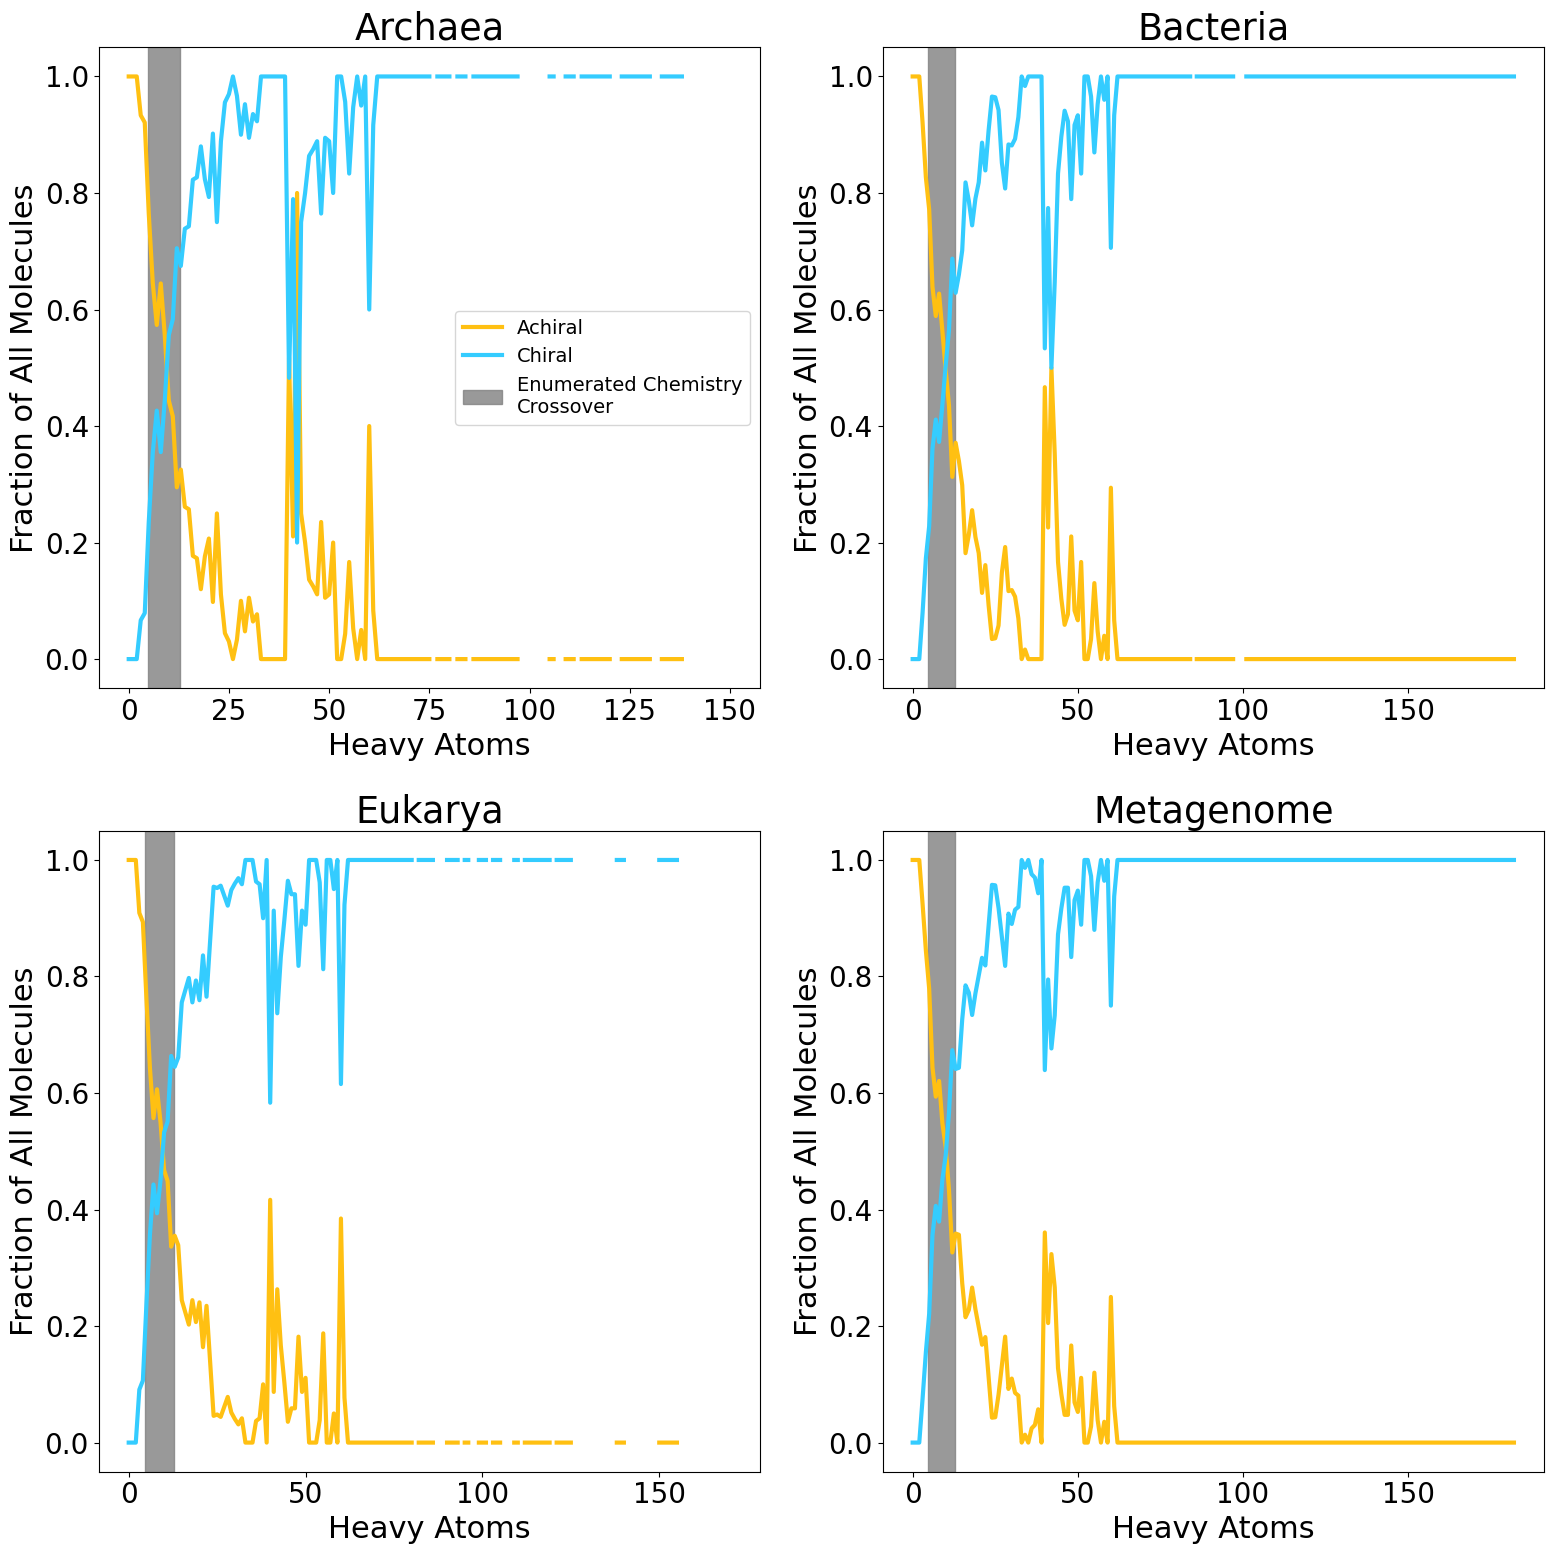

In [41]:
# fig_count = 16

fig, ax = plt.subplots(figsize=(16, 16))
toplot = ['Archaea', 'Bacteria', 'Eukarya', 'Metagenome']
ax = domain_achiral_fractions[toplot].plot(subplots=True, color=achiral_color, layout=(2, 2), legend=False, ax=ax,
                                           linewidth=3)
ax = domain_chiral_fractions[toplot].plot(subplots=True, color=chiral_color, layout=(2, 2), legend=False, ax=ax,
                                          linewidth=3,
                                          xlabel='Heavy Atoms', ylabel='Fraction of All Molecules',
                                          title=[i for i in toplot], fontsize=20)
for i in ax:
    i.axvspan(4.7, 12.7, alpha=0.8, color='grey')
ax[0].legend(labels=['Achiral', 'Chiral', 'Enumerated Chemistry\nCrossover'], fontsize=14, facecolor="white")

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

# Reaxys Sampling


In [42]:
#Matplotlib defaults
chnops_color = "#477C7D"
kegg_color = "#AA0E35"

chnops = pickle.load(file=open("../Data/chiral_chnops_sampling_FULL.p", "rb"))
kegg = pickle.load(file=open("../Data/chiral_kegg_sampling_FULL.p", "rb"))
mws = np.arange(100, 7100, 100)  #Molecular Weights (x-axis)

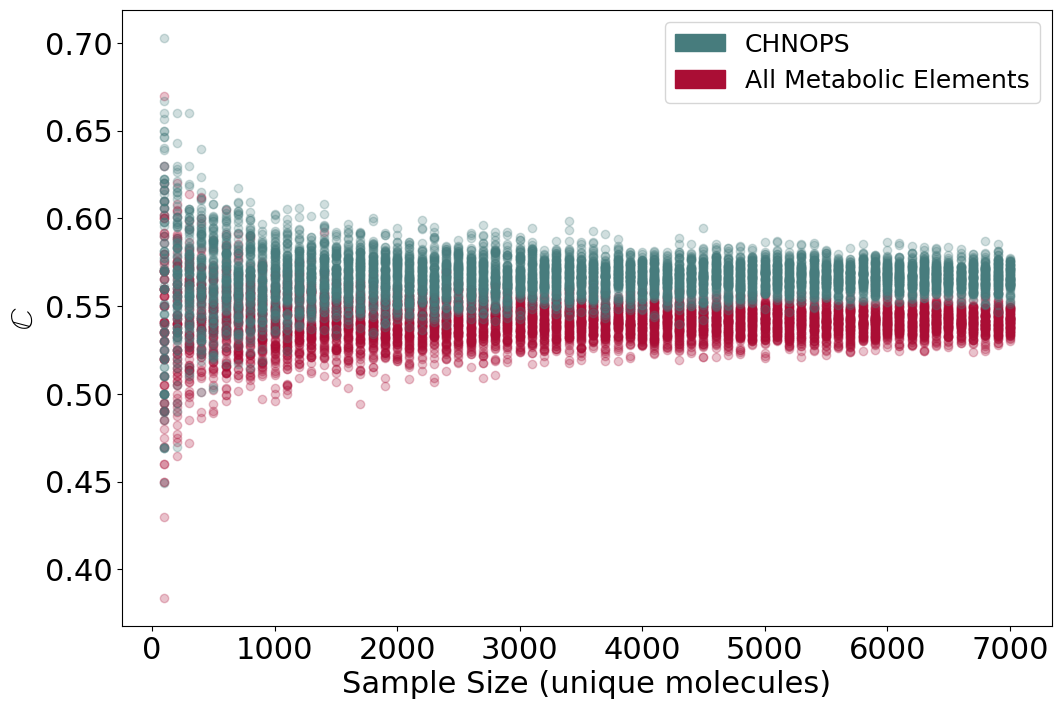

In [43]:
# fig_count = 17

fig, ax = plt.subplots(figsize=(12, 8))

#Scatter plot first
for i in range(len(chnops)):
    ax.scatter([mws[i]] * len(kegg[i]), kegg[i], color=kegg_color, alpha=0.25)
    ax.scatter([mws[i]] * len(chnops[i]), chnops[i], color=chnops_color, alpha=0.25)

ax.set_ylabel(r"$\mathbb{C}$", size=22)
ax.set_xlabel("Sample Size (unique molecules)", size=22)

ax.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='All Metabolic Elements')

ax.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1


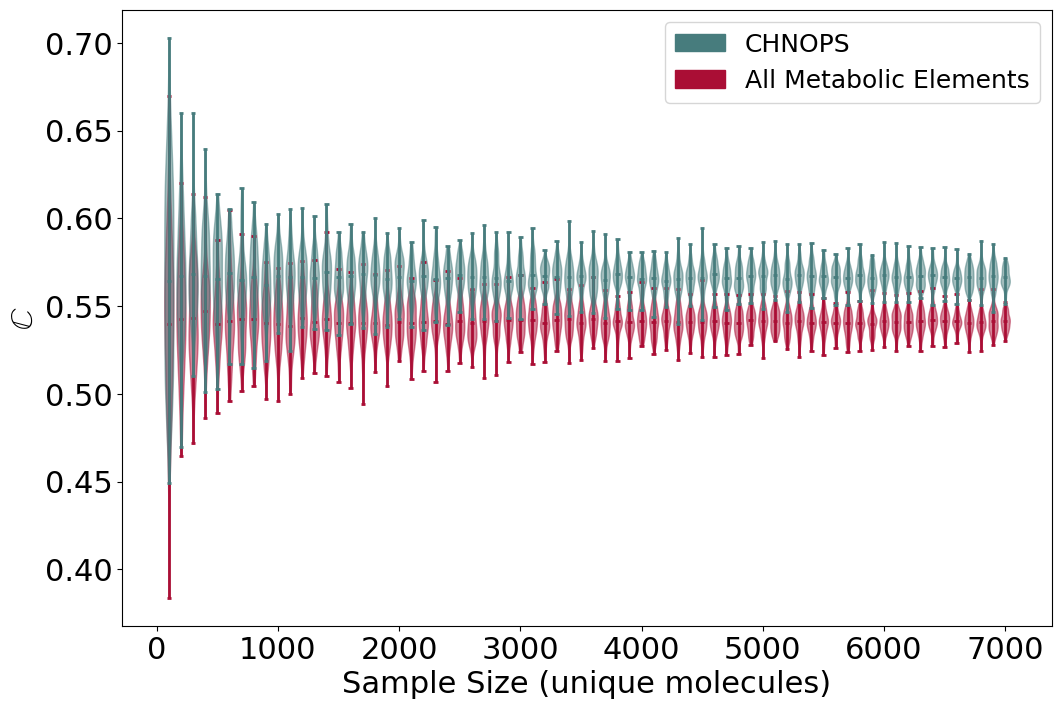

In [44]:
# fig_count = 18

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

#Violin plots second
kegg_violins = ax.violinplot(kegg, positions=mws, widths=75, showmeans=True)
chnops_violins = ax.violinplot(chnops, positions=mws, widths=75, showmeans=True)

# Color all CHNOPS violins
for partname in ('cbars', 'cmins', 'cmaxes', 'cmeans'):
    vp = chnops_violins[partname]
    vp.set_edgecolor(chnops_color)
    vp.set_linewidth(2)

for pc in chnops_violins['bodies']:
    pc.set_facecolor(chnops_color)
    pc.set_edgecolor(chnops_color)
    pc.set_alpha(0.5)

#Now do all KEGG violins
for partname in ('cbars', 'cmins', 'cmaxes', 'cmeans'):
    vp = kegg_violins[partname]
    vp.set_edgecolor(kegg_color)
    vp.set_linewidth(2)

for pc in kegg_violins['bodies']:
    pc.set_facecolor(kegg_color)
    pc.set_edgecolor(kegg_color)
    pc.set_alpha(0.5)

ax.set_ylabel(r"$\mathbb{C}$", size=22)
ax.set_xlabel("Sample Size (unique molecules)", size=22)

ax.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='All Metabolic Elements')

plt.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

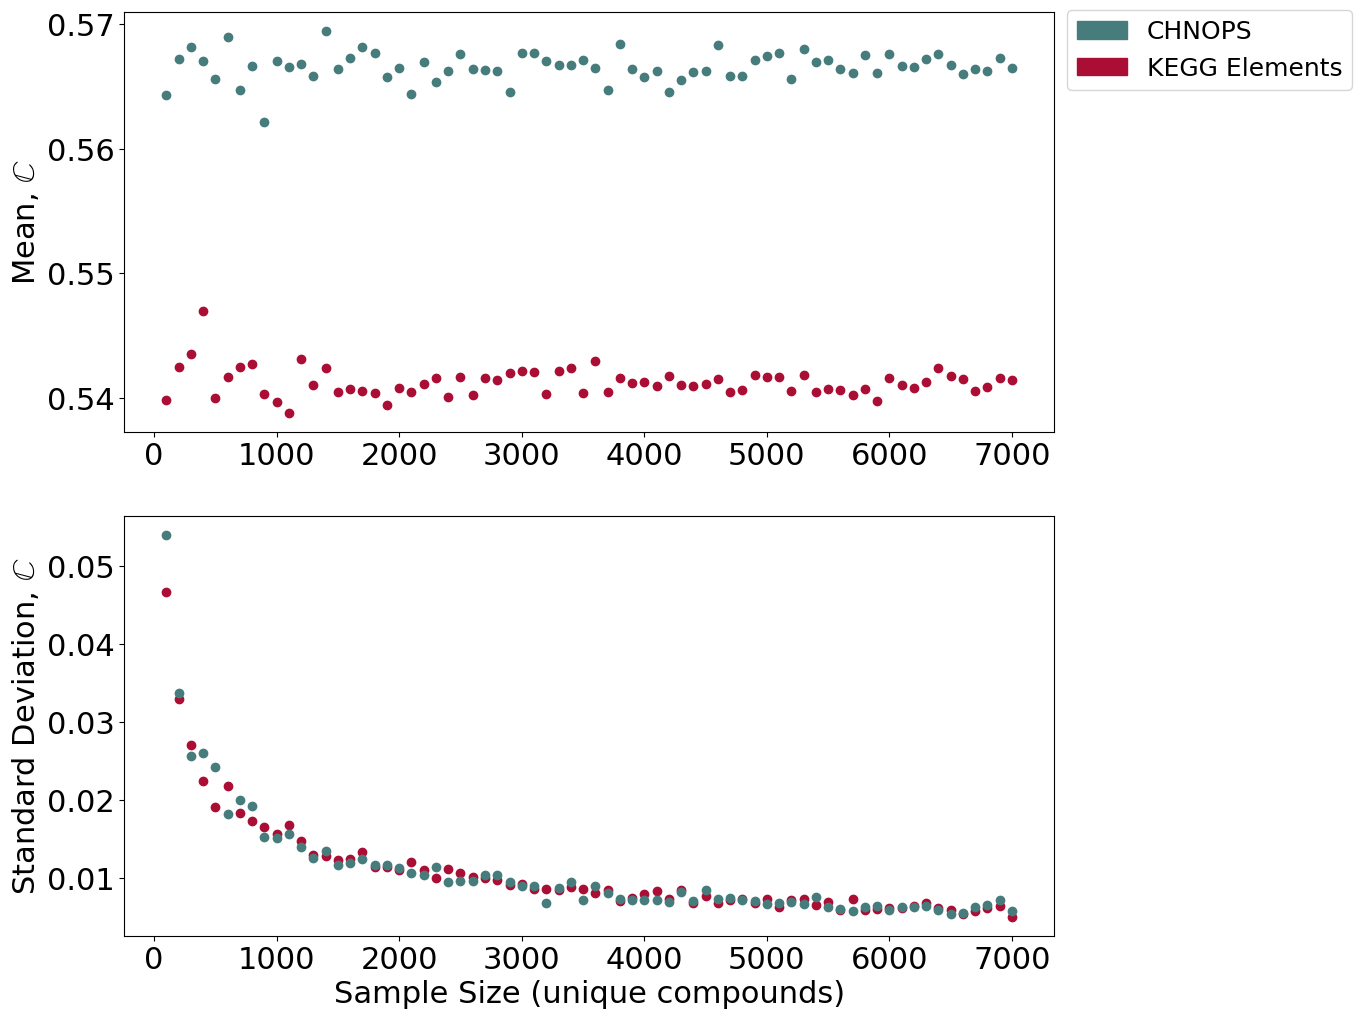

In [45]:
# fig_count = 19

## Mean & StdDev of all samples
plt.figure(figsize=(12, 12))
gs = gridspec.GridSpec(2, 1)

#Means
ax1 = plt.subplot(gs[0, 0])
ax1.scatter(mws, [np.mean(s) for s in kegg], color=kegg_color)
ax1.scatter(mws, [np.mean(s) for s in chnops], color=chnops_color)
ax1.set_ylabel(r"Mean, $\mathbb{C}$", size=22)
ax1.tick_params(axis='both', which='major', labelsize=22)

#Stdevs
ax2 = plt.subplot(gs[1, 0])
ax2.scatter(mws, [np.std(s) for s in kegg], color=kegg_color)
ax2.scatter(mws, [np.std(s) for s in chnops], color=chnops_color)
ax2.set_ylabel(r"Standard Deviation, $\mathbb{C}$", size=22)
ax2.set_xlabel("Sample Size (unique compounds)", size=22)
ax2.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

ax1.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18}, bbox_to_anchor=(1, 1.035))

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1

# Chiral Conserving Explanation

Figure in SI and not code-generated, adding one to figure count to account for it

In [46]:
fig_count += 1

# Pathways

In [47]:
url = "https://rest.kegg.jp/get/br:br08901/json"
r = requests.get(url)
data = r.json()

# metabolism_group_names = ["Carbohydrate metabolism", "Glycan biosynthesis and metabolism", "Terpenoids and Polyketides", 
#                           "Lipid Metabolism", "Secondary Metabolite Biosynthesis",
#                           "Nucleotide Metabolism", "Amino Acid Metabolism", "Metabolism of Other Amino Acids", 
#                           "Cofactors and Vitamins", "Energy Metabolism","Xenobiotics"]
metabolism_group_names = ["Carbohydrate metabolism", "Energy metabolism", "Lipid metabolism", "Nucleotide metabolism",
                          "Amino acid metabolism", "Metabolism of other amino acids", "Glycan biosynthesis and metabolism",
                          "Metabolism of cofactors and vitamins", "Metabolism of terpenoids and polyketides",
                          "Biosynthesis of other secondary metabolites", "Xenobiotics biodegradation and metabolism"]
metabolism_groups = {}
for group_name in metabolism_group_names:
    metabolism_groups[group_name] = []

for map in data["children"]:
    if map["name"] == "Metabolism":
        for m in map["children"]:
            if m["name"] in metabolism_group_names:
                for c in m["children"]:
                    metabolism_groups[m["name"]].append(int(c["name"].split()[0]))


In [48]:
### Get pathway names & cpd lists from KEGG (see slack for API calls)
session = prepare_session()
pathway_cpd_links, pathway_names = get_pathway_data(session=session)
pathway_chiralPercentage = dict()
pathway_size = dict()

### Get chirality of each pathway
print("- Calculating chiral percentage of pathways -")
keggC_df['compound_id'] = keggC_df.index
for pathway in tqdm(pathway_cpd_links.keys()):
    pathway_chiralPercentage[pathway], pathway_size[
        pathway] = get_chiral_percentage_from_list(
        pathway_cpd_links[pathway], keggC_df)

pathway_df = pd.DataFrame(
    [pathway_chiralPercentage, pathway_names,
     pathway_size]).transpose().dropna().sort_values(by=[0],
                                                     ascending=False)
pathway_df = pathway_df.rename(columns={
    0: "Chirality",
    1: "Name",
    2: "Size"
})

pathway_df['ID'] = pathway_df.index
# Get color setup & information
print("- Getting color schema -")
pathway_df, chiralities, pathway_group_colors, metabolism_groups, colors, color_list = get_pathway_colors(pathway_df)

#Hardcoding metabolic pathway colors & keys for graphing. Available in KEGG.

colors = {"Carbohydrate Metabolism": "#aa0f35",
          "Glycan Biosynthesis": "#487c7c",
          "Terpenoids and Polyketides": "#009ecb",
          "Lipid Metabolism": "#abdbfc",
          "Secondary Metabolite Biosynthesis": "#430057",
          "Nucleotide Metabolism": "#a0a75c",
          "Amino Acid Metabolism": "#603734",
          "Metabolism of Other Amino Acids": "#d97e43",
          "Cofactors and Vitamins": "#313a61",
          "Energy Metabolism": "#fdc799",
          "Xenobiotics": "#f5c500"}

pathway_group_keys = {"Carbohydrate Metabolism": 1,
                      "Glycan Biosynthesis": 2,
                      "Terpenoids and Polyketides": 3,
                      "Lipid Metabolism": 4,
                      "Secondary Metabolite Biosynthesis": 5,
                      "Nucleotide Metabolism": 6,
                      "Amino Acid Metabolism": 7,
                      "Metabolism of Other Amino Acids": 8,
                      "Cofactors and Vitamins": 9,
                      "Energy Metabolism": 10,
                      "Xenobiotics": 11}

color_list = ["#aa0f35",
              "#487c7c",
              "#009ecb",
              "#abdbfc",
              "#430057",
              "#a0a75c",
              "#603734",
              "#d97e43",
              "#fdc799",
              "#313a61",
              "#f5c500"]


def set_box_color(bp, color):
    plt.setp(bp['boxes'], color=color)
    plt.setp(bp['whiskers'], color=color)
    plt.setp(bp['caps'], color=color)
    plt.setp(bp['medians'], color=color)

- Getting KEGG pathway-compound links -
- Getting KEGG pathway names -
- Calculating chiral percentage of pathways -


100%|██████████| 459/459 [00:00<00:00, 1259.71it/s]

- Getting color schema -


/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/2338499457.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/2338499457.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/2338499457.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)
/var/folders/9c/_76vr8557qx_cryvn04pbpwr0000gn/T/ipykernel_79027/2338499457.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. afte

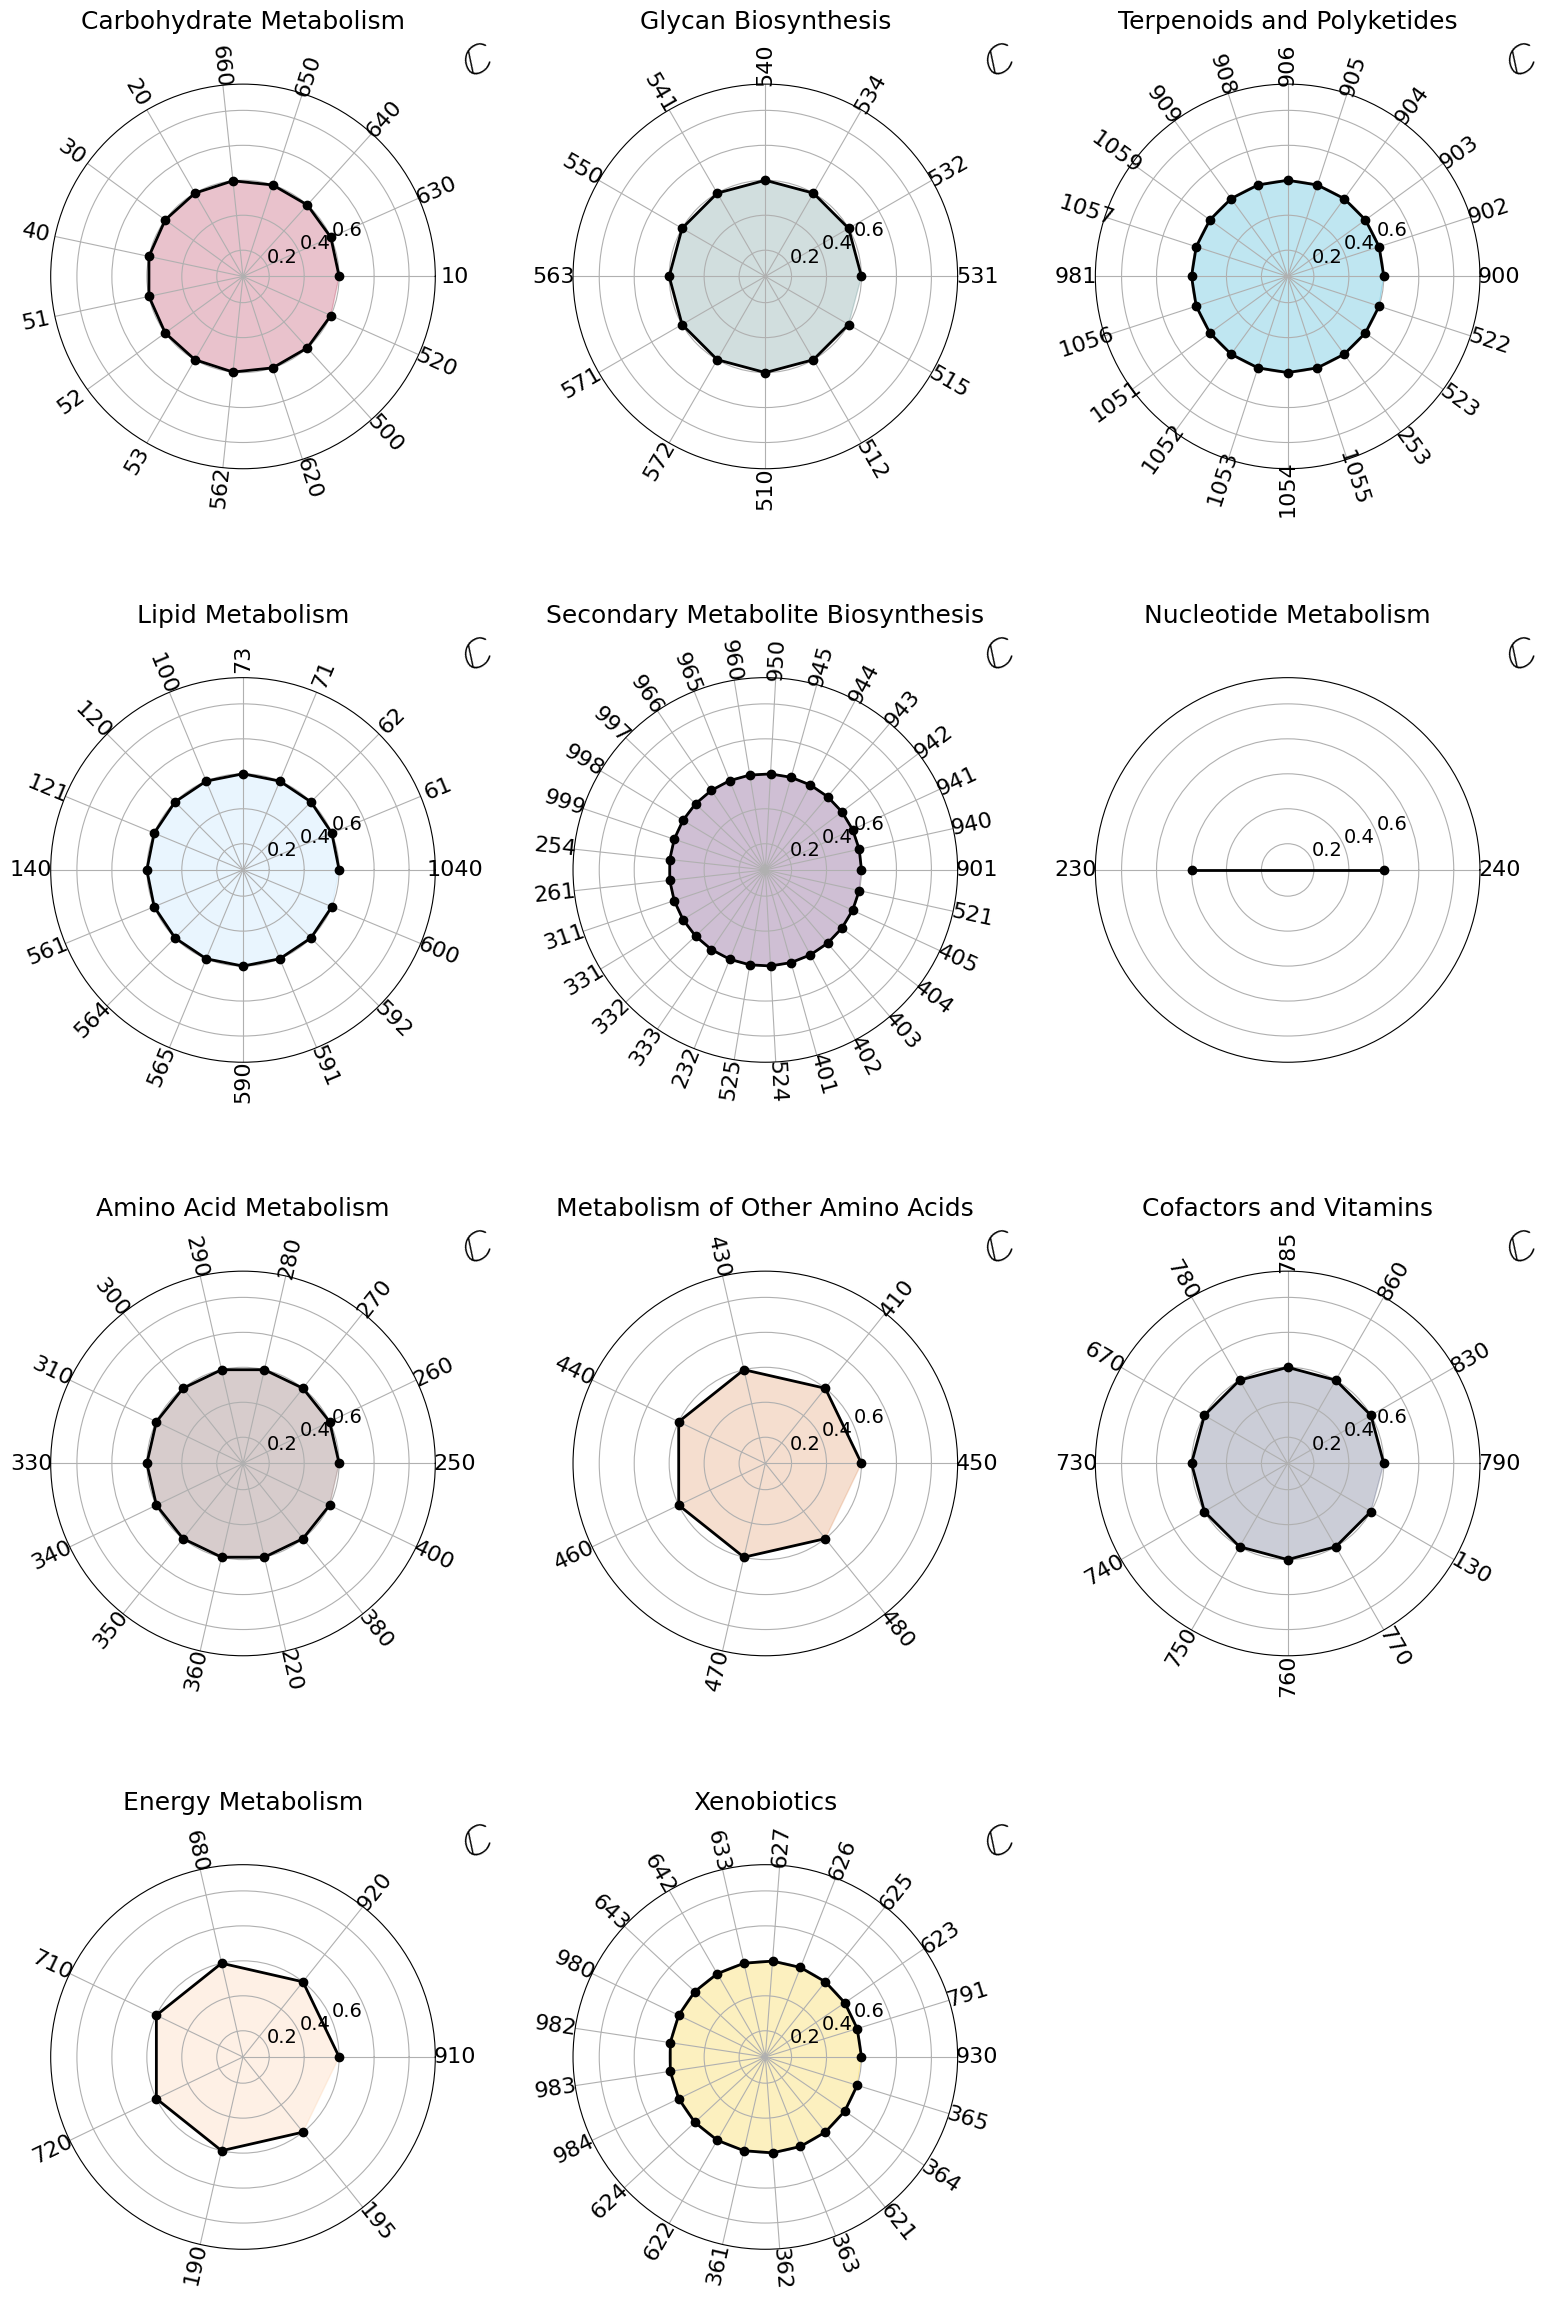

In [49]:
# fig_count = 20

plt.figure(figsize=(16, 24))
gs = gridspec.GridSpec(4, 3)

xcount = 0
ycount = 0

for group in list(metabolism_groups.keys()):
    #Label with pathway number
    sub_df = pathway_df[pathway_df["Group"] == group]
    labels = sub_df['ID'].tolist()

    # print(labels)

    #Define each angle for plotting
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
    stats = sub_df['Chirality'].tolist()
    # print(stats)

    ax = plt.subplot(gs[xcount, ycount], polar=True)
    #ax = fig.add_subplot(polar=True)
    ax.plot(angles, stats, 'o-', linewidth=2, color="k")
    ax.fill(angles, stats, alpha=0.25, color=colors[group])
    ax.set_thetagrids(angles * 180 / np.pi, labels, )

    #Make all angles rotated according to placement on the image
    #plt.gca.canvas.draw()
    angles[np.cos(angles) < 0] = angles[np.cos(angles) < 0] + np.pi
    angles = np.rad2deg(angles)
    # print(angles)
    for label, angle in zip(ax.get_xticklabels(), angles):
        # print(label, angle)
        x, y = label.get_position()
        try:
            lab = ax.text(x, y, int(float(label.get_text())), transform=label.get_transform(),
                          ha=label.get_ha(), va=label.get_va(), color="k",
                          fontsize=16)
        except:
            lab = ax.text(x, y, label.get_text(), transform=label.get_transform(),
                          ha=label.get_ha(), va=label.get_va(), color='k', fontsize=14)
        lab.set_rotation(angle)
        labels.append(lab)
    ax.set_xticklabels([])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)

    #label chiral percentage 
    label_pos = ax.get_rlabel_position()
    ax.text(np.radians(label_pos + 20), ax.get_rmax() / 2. + 0.1, r"$\mathbb{C}$",
            rotation=label_pos + 4, ha='center', va='center', fontsize=30, weight="bold")
    ax.set_title(group, pad=40, fontsize=18)

    if ycount == 2:
        xcount += 1
        ycount = 0
    else:
        ycount += 1

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count += 1